# Lezione 10 — Caso TakeHome: Lehman Brothers 2008: rischio sistemico, migrazioni creditizie e perdita di portafoglio

**Specifica vincolante:** La Scheda Caso costituisce la **specifica vincolante del lavoro**. Variabili, stati, parametri, formule, ipotesi, output e controlli indicati non devono essere modificati durante lo svolgimento.

---

## 1. Sintesi del caso

### Titolo e contesto

Il caso (*Lezione 10 — Applicazione in Python: rischio di credito*, tipologia *TakeHome*) è intitolato **Lehman Brothers 2008: rischio sistemico, migrazioni creditizie e perdita di portafoglio** ed è collocato nel giugno 2008, in una fase di crescente tensione del sistema finanziario internazionale e di deterioramento del merito creditizio di Lehman Brothers.

Il lavoro prevede lo sviluppo, mediante simulazione Monte Carlo su un orizzonte annuale ($T = 4$ trimestri), di un modello di rischio creditizio di portafoglio su 40 debitori in cui le migrazioni individuali di rating dipendono da un regime sistemico comune che evolve nel tempo secondo una catena di Markov. Il portafoglio concentrato iniziale (con una posizione rilevante su Lehman Brothers) viene confrontato con un portafoglio controfattuale a 39 debitori ottenuto eliminando la posizione Lehman e riallocandone proporzionalmente l'investimento sui restanti debitori a investimento complessivo invariato.

### Domanda quantitativa

Quale distribuzione della perdita a un anno produce il portafoglio concentrato e come cambiano perdita attesa, dispersione, VaR e CVaR quando l'investimento inizialmente concentrato su Lehman Brothers viene riallocato proporzionalmente tra gli altri debitori, a investimento complessivo invariato?

### Variabile finale

La variabile finale di interesse è la **perdita monetaria di portafoglio a un anno** ($T = 4$ trimestri), espressa in milioni di dollari, per il portafoglio concentrato:

$$
L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}
$$

e per il portafoglio controfattuale:

$$
L_{\mathrm{div}}^{P,(r)} = \sum_{i\neq L} V_{i,0}^{\mathrm{div}} \, \varphi\left(X_{i,0}, X_{i,4}^{(r)}\right)
$$

unitamente alla differenza replica per replica $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.

### Informazione disponibile

- **Portafoglio iniziale concentrato:** 40 debitori con esposizione complessiva deterministica $V_0^{P,\mathrm{conc}} = 173$ milioni di dollari (1 posizione Lehman Brothers in classe $A$ da $25$ milioni; 11 debitori $A$ da $5$ milioni ciascuno; 14 debitori $BBB$ da $4$ milioni ciascuno; 9 debitori $BB$ da $3$ milioni ciascuno; 5 debitori $B$ da $2$ milioni ciascuno).

- **Portafoglio controfattuale:** 39 debitori ottenuti eliminando Lehman Brothers e ridistribuendo i $25$ milioni sui restanti $148$ milioni mediante il fattore di riscalamento $\frac{173}{148} \approx 1.168919$, mantenendo invariato l'investimento totale ($V_0^{P,\mathrm{div}} = 173$ milioni di dollari).

- **Processo del regime sistemico:** catena di Markov omogenea trimestrale $\{M_t\}_{t=0}^{3}$ sullo spazio degli stati $\mathcal{M} = \{O, S, C\}$ (condizioni ordinarie, stress finanziario, crisi), con stato iniziale $M_0 = S$ e matrice di transizione assegnata $Q$.

- **Processo di migrazione creditizia individuale:** per ciascun debitore $i$, catena $\{X_{i,t}\}_{t=0}^{4}$ sullo spazio degli stati $\mathcal{I} = \{A, BBB, BB, B, D\}$ (con stato di default $D$ assorbente), regolata dalle matrici di transizione trimestrali condizionate al regime sistemico corrente $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$, con indipendenza delle migrazioni individuali condizionatamente alla traiettoria sistemica comune.

- **Parametri di esposizione e perdita:** $\mathrm{EAD}_i = V_{i,0}$, $\mathrm{LGD} = 0.65$ costante, e tabella deterministica dei tassi di perdita migration-based $\varphi(r_0, r_4)$ in funzione del rating iniziale $r_0$ e finale $r_4$ (con $\varphi(r_0, D) = 0.65$).

- **Parametri computazionali e di confronto:** $N_{\mathrm{MC}} = 50\,000$ repliche Monte Carlo, $\text{seed} = 2026$, orizzonte $T = 4$ trimestri, e utilizzo delle medesime repliche sottostanti (stessa traiettoria sistemica e stesse traiettorie creditizie per i 39 debitori comuni) nei due portafogli.

---

## 2. Quantità da stimare o calcolare

### Misure da determinare per entrambi i portafogli (concentrato e controfattuale)

1. La perdita media:

$$
\mathbb{E}[L^P]
$$

2. La varianza:

$$
\operatorname{Var}(L^P)
$$

3. La deviazione standard.

4. Il Value at Risk ai livelli $95\%$ e $99\%$:

$$
\operatorname{VaR}_{0,95}(L^P), \qquad \operatorname{VaR}_{0,99}(L^P)
$$

5. Il Conditional Value at Risk ai livelli $95\%$ e $99\%$ (calcolato secondo la definizione mediante quantili adottata nel Capitolo 9):

$$
\operatorname{CVaR}_{0,95}(L^P), \qquad \operatorname{CVaR}_{0,99}(L^P)
$$

### Ulteriori quantità relative al regime sistemico e al confronto tra portafogli

6. La probabilità che il regime $C$ venga raggiunto almeno una volta durante l'orizzonte.

7. La perdita media del portafoglio concentrato nelle repliche nelle quali il regime $C$ viene raggiunto almeno una volta e nelle repliche nelle quali il regime $C$ non viene mai raggiunto.

8. Per ciascuna misura di rischio $\rho$, la variazione tra portafoglio controfattuale e portafoglio concentrato:

$$
\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)
$$

9. La differenza replica per replica tra le perdite dei due portafogli:

$$
\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}
$$

---

## 3. Output richiesti

### 6.1 Risultati numerici

Per entrambi i portafogli (concentrato e controfattuale):

- distribuzione simulata della perdita;

- perdita media;

- varianza;

- deviazione standard;

- VaR 95%;

- CVaR 95%;

- VaR 99%;

- CVaR 99%.

Inoltre:

- differenze tra le misure di rischio dei due portafogli;

- probabilità simulata che il regime $C$ venga raggiunto almeno una volta;

- perdita media del portafoglio concentrato nelle repliche con e senza ingresso nello stato $C$;

- distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.

### 6.2 Tabelle

- **Tabella 1 — Portafoglio iniziale concentrato:** rating iniziale, numero di debitori, investimento individuale e investimento complessivo.

- **Tabella 2 — Portafoglio controfattuale:** rating iniziale, numero di debitori, investimento individuale riallocato e investimento complessivo.

- **Tabella 3 — Misure di rischio:** confronto tra portafoglio concentrato, portafoglio con riallocazione proporzionale e differenza tra le rispettive misure.

- **Tabella 4 — Regime sistemico e perdita:** confronto, per il portafoglio concentrato, tra repliche con e senza ingresso nello stato $C$.

### 6.3 Grafici

- **Figura 1 — Distribuzione della perdita del portafoglio concentrato:** distribuzione empirica di $L_{\mathrm{conc}}^P$ con indicazione di VaR 95% e VaR 99%.

- **Figura 2 — Confronto delle distribuzioni:** confronto tra le distribuzioni empiriche delle perdite del portafoglio concentrato e del portafoglio controfattuale, con particolare attenzione alla coda destra.

- **Figura 3 — Regime sistemico e perdita:** confronto delle perdite del portafoglio concentrato tra repliche nelle quali lo stato $C$ viene raggiunto almeno una volta e repliche nelle quali non viene mai raggiunto.

---

## 4. Controlli richiesti

### Controlli numerici

- **Controllo 1:** Verifica che ogni riga della matrice di transizione del regime sistemico $Q$ sommi a 1.

- **Controllo 2:** Verifica che ogni riga delle matrici di migrazione creditizia $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sommi a 1.

- **Controllo 7:** Verifica che il portafoglio concentrato contenga esattamente 40 debitori.

- **Controllo 8:** Verifica che il portafoglio controfattuale contenga esattamente 39 debitori.

- **Controllo 9:** Verifica che l'investimento iniziale complessivo sia pari a 173 milioni di dollari in entrambi i portafogli ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$).

- **Controllo 10:** Verifica che le proporzioni relative degli investimenti dei 39 debitori residui rimangano inalterate dopo la riallocazione proporzionale.

- **Controllo 12:** Verifica che la perdita totale di ciascun portafoglio coincida con la somma delle rispettive perdite individuali.

- **Controllo 14:** Verifica che VaR e CVaR siano calcolati sulle distribuzioni empiriche delle perdite monetarie, espresse in milioni di dollari.

- **Controllo 15:** Verifica che le principali misure di rischio mostrino una ragionevole stabilità al crescere del numero di repliche simulate.

### Controlli logici o teorici

- **Controllo 3:** Verifica che lo stato $D$ sia assorbente in tutte le matrici di migrazione creditizia ($p_{DD}^{(m)} = 1$).

- **Controllo 4:** Verifica che tutti gli stati simulati appartengano agli insiemi definiti ($\mathcal{M} = \{O, S, C\}$ e $\mathcal{I} = \{A, BBB, BB, B, D\}$).

- **Controllo 5:** Verifica che, all'interno della stessa replica Monte Carlo, esista un'unica traiettoria sistemica comune a tutti i debitori.

- **Controllo 6:** Verifica che, condizionatamente alla traiettoria sistemica comune, i debitori utilizzino estrazioni casuali individuali e indipendenti.

### Controlli computazionali

- **Controllo 11:** Verifica che i 39 debitori comuni utilizzino esattamente le stesse traiettorie creditizie nei due portafogli.

- **Controllo 13:** Verifica che il seed assegnato, pari a 2026, sia impostato correttamente come condizione per la riproducibilità della simulazione.

# Flusso logico-teorico risolutivo — Rischio di credito sistemico e confronto di portafoglio

## Verifica della sequenza teorica proposta

La sequenza elaborata individua correttamente i nuclei fondamentali del modello (portafogli iniziale e controfattuale, doppia catena di Markov con fattore sistemico comune, stato assorbente $D$, indipendenza condizionata, tassi di perdita migration-based, simulazione Monte Carlo con traiettorie condivise, misure di rischio e controlli). Per renderla pienamente coerente con l'ordine causale del modello probabilistico e con la struttura della Scheda Caso, si segnalano i seguenti affinamenti:

- **Elementi fuori ordine:**
  - *Valutazione delle perdite vs. struttura dei portafogli e processi stocastici:* nel flusso causale del modello, la definizione statica dei due portafogli e delle esposizioni (punto 3) e la specifica delle catene di Markov $M_t$ e $X_{i,t}$ (punto 2) precedono logicamente l'applicazione della funzione di perdita $\varphi(X_{i,0}, X_{i,4})$ e l'aggregazione delle perdite di portafoglio (inserite al punto 1), poiché la perdita è una funzione dello stato terminale generato dai processi.
  - *Parametri del modello vs. parametri Monte Carlo:* l'orizzonte $T = 4$ trimestri appartiene alla definizione teorica dei processi stocastici, mentre $N_{\mathrm{MC}} = 50\,000$, il $\text{seed} = 2026$ e l'abbinamento delle traiettorie (*Common Random Numbers*) appartengono alla fase di stima Monte Carlo.
  - *Collocazione dei controlli:* i controlli assiomatici e strutturali sulle matrici e sui portafogli (Controlli 1, 2, 3, 7, 8, 9, 10) precedono logicamente l'esecuzione della simulazione, mentre i controlli sulle traiettorie simulate e sugli stimatori (Controlli 4, 5, 6, 11, 12, 13, 14, 15) la seguono.

- **Elementi mancanti o impliciti da esplicitare:**
  - *Ipotesi di omogeneità temporale e misura fisica:* va esplicitato che $\{M_t\}_{t=0}^3$ e $\{X_{i,t}\}_{t=0}^4$ (condizionatamente al regime) sono catene di Markov omogenee nel tempo definite sotto probabilità fisiche.
  - *Allineamento degli indici temporali e irrilevanza del momento di default:* va precisato che $M_t$ evolve per $t \in \{0, 1, 2, 3\}$ (quattro regimi trimestrali che governano le quattro transizioni) mentre $X_{i,t}$ evolve per $t \in \{0, 1, 2, 3, 4\}$, e che grazie all'assorbenza di $D$ e alla costanza di $\mathrm{LGD} = 0.65$ la perdita da default dipende esclusivamente dallo stato terminale $X_{i,4} = D$ e non dal trimestre in cui il default avviene.
  - *Formulazione matematica delle misure di coda e dell'evento di crisi:* occorre esplicitare la definizione mediante quantili di $\operatorname{VaR}_\alpha$ e $\operatorname{CVaR}_\alpha$ (richiamata dal Capitolo 9) e l'evento $E_C = \{\exists t \in \{0, 1, 2, 3\} : M_t = C\}$ per la stima della probabilità di crisi e delle medie condizionate.
  - *Natura del confronto controfattuale:* va richiamato sul piano teorico che la riallocazione proporzionale modifica anche la composizione dell'investimento per classe di rating; pertanto $\Delta\rho$ non isola un effetto puro di concentrazione, ma misura l'effetto congiunto della strategia controfattuale assegnata.

- **Elementi ridondanti o da disaggregare:**
  - Il punto 5 accorpa tre passaggi teoricamente distinti: (i) la generazione delle traiettorie markoviane, (ii) il calcolo delle perdite individuali e di portafoglio e (iii) la stima delle misure di rischio, delle quantità condizionate al regime $C$ e delle differenze tra portafogli. Nella tabella sottostante tali passaggi sono stati separati per chiarezza logica.
  - Il punto 7 (interpretazione finale) corrisponde alla Fase 8 autonoma dello studente e non a un passaggio di calcolo del modello; nel flusso teorico esso è integrato nella predisposizione delle metriche comparative e condizionate necessarie al commento conclusivo.

---

## Sequenza teorica ordinata e completa

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | **Definizione della struttura dei portafogli ed esposizioni iniziali** | Semplificazione di esposizione deterministica $\mathrm{EAD}_i = V_{i,0}$. Esposizione complessiva concentrata $V_0^{P,\mathrm{conc}} = \sum_{i=1}^{40} V_{i,0}$. Riallocazione proporzionale controfattuale per $i \neq L$: $V_{i,0}^{\mathrm{div}} = V_{i,0} + V_{L,0}\frac{V_{i,0}}{\sum_{j \neq L} V_{j,0}} = V_{i,0}\frac{V_0^{P,\mathrm{conc}}}{V_0^{P,\mathrm{conc}} - V_{L,0}}$, con invarianza dell'investimento totale $V_0^{P,\mathrm{div}} = \sum_{i \neq L} V_{i,0}^{\mathrm{div}} = V_0^{P,\mathrm{conc}}$. | Portafoglio concentrato su $40$ debitori con $V_0^{P,\mathrm{conc}} = 173$ mln USD (Lehman Brothers $V_{L,0} = 25$ mln in classe $A$; $39$ altri debitori per $148$ mln). Portafoglio controfattuale su $39$ debitori con fattore di riscalamento $\frac{173}{148} \approx 1.168919$ e $V_0^{P,\mathrm{div}} = 173$ mln USD, con conseguente variazione dei pesi per classe di rating. | Tabella 1; Tabella 2; Controllo 7 ($40$ debitori); Controllo 8 ($39$ debitori); Controllo 9 ($V_0^P = 173$); Controllo 10 (invarianza proporzioni relative dei $39$ debitori). |
| 2 | **Specifica della dinamica del regime sistemico comune** | Catena di Markov discreta, finita e omogenea nel tempo $\{M_t\}_{t=0}^{3}$ sullo spazio degli stati $\mathcal{M} = \{O, S, C\}$ sotto probabilità fisiche. Proprietà di Markov: $\mathbb{P}(M_{t+1} = n \mid M_t = m, M_{t-1}, \dots, M_0) = q_{mn}$. Proprietà stocastica della matrice di transizione $Q = (q_{mn})$: $q_{mn} \ge 0$ e $\sum_{n \in \mathcal{M}} q_{mn} = 1 \;\forall m \in \mathcal{M}$. | Stato iniziale deterministico $M_0 = S$ (stress finanziario a giugno 2008). Evoluzione per $t = 0, 1, 2$ tramite la matrice trimestrale $Q$ ($3 \times 3$) per generare un'unica traiettoria sistemica $(M_0, M_1, M_2, M_3)$ condivisa da tutti i debitori. | Controllo 1 (somma righe di $Q$ pari a $1$); Controllo 4 ($M_t \in \{O, S, C\}$); Controllo 5 (unicità della traiettoria sistemica per replica). |
| 3 | **Specifica delle migrazioni creditizie individuali condizionate al regime** | Catene di Markov $\{X_{i,t}\}_{t=0}^{4}$ su $\mathcal{I} = \{A, BBB, BB, B, D\}$ con transizioni condizionate al regime: $\mathbb{P}(X_{i,t+1} = j \mid X_{i,t} = k, M_t = m) = p_{kj}^{(m)}$ (omogenee a parità di regime $m$). Stato assorbente $D$: $p_{DD}^{(m)} = 1$ e $p_{Dj}^{(m)} = 0 \;\forall j \neq D$. Indipendenza condizionata: dato $(M_0, M_1, M_2, M_3)$, le traiettorie $\{X_{i,t}\}_{t=0}^4$ dei diversi debitori sono indipendenti (dipendenza incondizionata indotta dal regime comune). | A partire dai rating iniziali deterministici $X_{i,0}$, ogni debitore $i$ evolve trimestralmente per $t = 0, 1, 2, 3$ utilizzando la matrice $P^{(O)}$, $P^{(S)}$ o $P^{(C)}$ corrispondente a $M_t$, determinando il rating finale $X_{i,4}$. | Controllo 2 (somma righe di $P^{(O)}, P^{(S)}, P^{(C)}$ pari a $1$); Controllo 3 ($p_{DD}^{(m)} = 1$); Controllo 4 ($X_{i,t} \in \mathcal{I}$); Controllo 6 (indipendenza condizionata delle estrazioni individuali). |
| 4 | **Valutazione delle perdite individuali e di portafoglio** | Perdita individuale migration-based: $L_i = V_{i,0} \, \varphi(X_{i,0}, X_{i,4})$, dove $\varphi(r_0, r_4) < 0$ indica un incremento di valore da upgrade e $\varphi(r_0, D) = \mathrm{LGD}$ il tasso di perdita da default. Poiché $D$ è assorbente e $\mathrm{LGD}$ è costante, la perdita da default dipende solo da $X_{i,4} = D$ e non dal trimestre di default. Additività delle perdite di portafoglio: $L_{\mathrm{conc}}^{P} = \sum_{i=1}^{40} L_i$ e $L_{\mathrm{div}}^{P} = \sum_{i \neq L} V_{i,0}^{\mathrm{div}} \, \varphi(X_{i,0}, X_{i,4})$. | Applicazione della tabella deterministica $\varphi(r_0, r_4)$ (con $\mathrm{LGD} = 0.65$) tra $t=0$ e $t=4$ per ottenere le perdite individuali e le perdite complessive $L_{\mathrm{conc}}^{P,(r)}$ e $L_{\mathrm{div}}^{P,(r)}$ espresse in milioni di dollari. | Controllo 12 (coincidenza della perdita di portafoglio con la somma delle perdite individuali). |
| 5 | **Impostazione della simulazione Monte Carlo e abbinamento delle traiettorie** | Metodo Monte Carlo: campionamento di $N_{\mathrm{MC}}$ repliche indipendenti ed identicamente distribuite secondo la legge congiunta del modello (convergenza garantita dalla Legge dei Grandi Numeri). Tecnica dei Numeri Casuali Comuni (*Common Random Numbers*): utilizzo della medesima traiettoria sistemica $\{M_t^{(r)}\}_{t=0}^3$ e delle medesime traiettorie creditizie $\{X_{i,t}^{(r)}\}_{t=0}^4$ per i $39$ debitori comuni nella replica $r$-esima dei due portafogli. | Esecuzione di $N_{\mathrm{MC}} = 50\,000$ repliche sull'orizzonte $T = 4$ trimestri con $\text{seed} = 2026$ per generare le distribuzioni empiriche $\{L_{\mathrm{conc}}^{P,(r)}\}_{r=1}^{50\,000}$ e $\{L_{\mathrm{div}}^{P,(r)}\}_{r=1}^{50\,000}$. | Distribuzioni simulate della perdita; Figura 1; Figura 2; Controllo 11 (stesse traiettorie per i $39$ debitori comuni); Controllo 13 ($\text{seed} = 2026$); Controllo 15 (stabilità al crescere di $N_{\mathrm{MC}}$). |
| 6 | **Stima delle misure di sintesi e di rischio di coda** | Media campionaria $\widehat{\mathbb{E}}[L^P] = \frac{1}{N_{\mathrm{MC}}} \sum_{r=1}^{N_{\mathrm{MC}}} L^{P,(r)}$; varianza campionaria $\widehat{\operatorname{Var}}(L^P) = \frac{1}{N_{\mathrm{MC}}-1} \sum_{r=1}^{N_{\mathrm{MC}}} (L^{P,(r)} - \widehat{\mathbb{E}}[L^P])^2$ e deviazione standard $\widehat{\sigma}(L^P) = \sqrt{\widehat{\operatorname{Var}}(L^P)}$. Value at Risk al livello $\alpha$: quantile empirico $\widehat{\operatorname{VaR}}_\alpha(L^P) = F_{L^P, N_{\mathrm{MC}}}^{-1}(\alpha)$. Conditional Value at Risk al livello $\alpha$ (definizione mediante quantili del Capitolo 9): $\operatorname{CVaR}_\alpha(L^P) = \frac{1}{1-\alpha}\int_\alpha^1 \operatorname{VaR}_u(L^P)\,du$, stimato empiricamente sulla coda oltre $\widehat{\operatorname{VaR}}_\alpha(L^P)$. | Calcolo di perdita media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$ e $\operatorname{CVaR}_{0.99}$ (in milioni di dollari) per entrambi i portafogli. | Risultati numerici (Sez. 6.1); Tabella 3; Figura 1 (soglie $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$); Controllo 14 (unità monetarie in mln USD); Controllo 15 (stabilità delle stime). |
| 7 | **Analisi condizionata al regime di crisi e confronto differenziale** | Evento di ingresso nel regime $C$: $E_C = \{\exists t \in \{0, 1, 2, 3\} : M_t = C\}$, con probabilità stimata $\widehat{\mathbb{P}}(E_C) = \frac{1}{N_{\mathrm{MC}}} \sum_{r=1}^{N_{\mathrm{MC}}} \mathbb{I}_{E_C^{(r)}}$. Medie condizionate $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C]$ e $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C^c]$. Variazione delle misure di rischio $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ e differenza replica per replica $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$. | Quantificazione dell'impatto del regime $C$ sul portafoglio concentrato e valutazione della strategia controfattuale tramite $\Delta\rho$ e la distribuzione empirica di $\Delta L^{(r)}$ (tenendo conto dell'effetto combinato di deconcentralizzazione e ricomposizione tra classi di rating). | Risultati numerici (Sez. 6.1); Tabella 3; Tabella 4; Figura 2; Figura 3. |

---

> **Nota di validazione (Fase 4):** La revisione sopra proposta verifica e completa l'impianto teorico del lavoro; la validazione definitiva del Flusso logico-teorico risolutivo spetta allo studente prima di procedere alla scomposizione operativa del problema (Prompt 3).

# Scomposizione operativa del problema in tappe input-output

## Verifica, integrazione e riordino della scomposizione proposta

La scomposizione in 3 macro-tappe proposta individua correttamente la progressione generale del lavoro (inizializzazione e verifica dei dati, simulazione con traiettorie condivise, aggregazione delle perdite e stima delle misure di rischio). Dal confronto con la **Scheda Caso** e con il **Flusso logico-teorico risolutivo** già validato emergono tuttavia alcune incoerenze di collocazione, elementi da precisare e controlli mancanti:

### 1. Incoerenze rilevate rispetto al Flusso logico-teorico risolutivo e alla Scheda Caso

- **Collocazione anticipata di `Tabella 3` e delle differenze tra misure di rischio ($\Delta\rho$):** nella Tappa 1 della bozza viene richiesta la produzione di `Tabella 3 — Misure di rischio`, e nella Tappa 2 (a livello di singola simulazione) viene menzionata la *"variazione della misura di rischio"*. Nel Flusso validato (Passi 6 e 7), le misure di rischio ($\mathbb{E}[L^P]$, $\operatorname{Var}$, deviazione standard, $\operatorname{VaR}_\alpha$, $\operatorname{CVaR}_\alpha$) e le relative variazioni $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ sono grandezze distributive calcolate sull'intero campione simulato di $N_{\mathrm{MC}} = 50\,000$ repliche. A livello di singola replica $r$ si determina invece soltanto la differenza puntuale $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$. Pertanto, `Tabella 3` è stata spostata nella tappa di stima delle misure di rischio (Tappa 4).
- **Formulazione del Controllo 5 ("unica matrice di transizione"):** nella Tappa 2 della bozza si chiede di verificare che *"all'interno delle singole simulazioni, venga utilizzata un'unica matrice di transizione"*. Come stabilito nei Passi 2 e 3 del Flusso, all'interno della singola replica $r$ il regime sistemico $M_t^{(r)}$ evolve trimestralmente ($t = 0, 1, 2, 3$), per cui la matrice di migrazione creditizia $P^{(M_t^{(r)})}$ varia nel tempo in funzione del regime corrente. L'unicità richiesta dal **Controllo 5** riguarda invece la **traiettoria sistemica comune** $(M_0^{(r)}, M_1^{(r)}, M_2^{(r)}, M_3^{(r)})$, che deve essere la medesima per tutti i debitori nella stessa replica.
- **Fondamento teorico del Controllo 15:** nella Tappa 3 della bozza la stabilità delle principali misure di rischio al crescere di $N_{\mathrm{MC}}$ è ricondotta al *Teorema del Limite Centrale*. Si precisa che, mentre per la media campionaria operano la Legge dei Grandi Numeri e il Teorema del Limite Centrale, per i quantili empirici ($\operatorname{VaR}_\alpha$) e il $\operatorname{CVaR}_\alpha$ la stabilità asintotica discende dalla convergenza della funzione di ripartizione empirica (teorema di Glivenko-Cantelli) e dalla consistenza degli stimatori di coda.

### 2. Controlli e output della Scheda Caso mancanti o impliciti nella bozza

- **Controllo 4 (mancante):** verifica che tutti gli stati simulati appartengano agli insiemi $\mathcal{M} = \{O, S, C\}$ e $\mathcal{I} = \{A, BBB, BB, B, D\}$ (inserito nella Tappa 2).
- **Controllo 11 (implicito):** verifica esplicita che i $39$ debitori comuni utilizzino esattamente le stesse traiettorie creditizie nei due portafogli (esplicitato nella Tappa 2).
- **Controllo 13 (implicito):** verifica esplicita della corretta impostazione del $\text{seed} = 2026$ per la riproducibilità della simulazione (esplicitato nella Tappa 2).
- **Controllo integrativo proposto dallo studente:** il confronto tra la probabilità empirica e la probabilità teorica di raggiungere almeno una volta lo stato $C$ (indicato nella Tappa 3 della bozza) non rientra tra i 15 controlli numerati della Scheda Caso, ma è stato mantenuto nella Tappa 5 come controllo integrativo di coerenza markoviana senza alterare la numerazione vincolante (Controlli 1–15).

### 3. Articolazione progressiva delle tappe

Per consentire una costruzione graduale e verificabile del notebook, le 3 macro-tappe iniziali sono state articolate in **6 tappe input-output** ordinatamente allineate ai Passi 1–7 del Flusso logico-teorico risolutivo, coprendo integralmente tutti gli output (Sezione 6) e tutti i controlli (Sezione 7) della Scheda Caso.

---

## Piano operativo ordinato in tappe input-output

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| 1 | **Inizializzazione dei parametri, verifica delle matrici e costruzione dei portafogli** | Acquisire i parametri strutturali del modello, verificare le proprietà stocastiche delle matrici, costruire il portafoglio concentrato e quello controfattuale e produrre le tabelle descrittive iniziali. | Spazi degli stati $\mathcal{M}$ e $\mathcal{I}$; stato iniziale $M_0 = S$; matrici $Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$; matrice dei tassi di perdita $\varphi$; $\mathrm{LGD} = 0.65$; composizione e investimenti iniziali $V_{i,0}$ dei $40$ debitori. | **Passo 1** (portafogli ed esposizioni $\mathrm{EAD}_i = V_{i,0}$, riallocazione proporzionale con fattore $\frac{173}{148}$); **Passo 2** (matrice $Q$); **Passo 3** (matrici $P^{(m)}$ e stato assorbente $D$); **Passo 4** (funzione $\varphi$). | Definizione delle strutture dati per stati, matrici di transizione e tabella $\varphi$; costruzione del portafoglio concentrato ($40$ debitori) e calcolo delle esposizioni riallocate $V_{i,0}^{\mathrm{div}}$ ($39$ debitori); generazione di **Tabella 1** e **Tabella 2**. | Oggetti validati ($Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$, $\varphi$, rating iniziali $X_{i,0}$, vettori $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$); **Tabella 1 — Portafoglio iniziale concentrato**; **Tabella 2 — Portafoglio controfattuale**. | **Controllo 1** (somma righe $Q = 1$); **Controllo 2** (somma righe $P^{(m)} = 1$); **Controllo 3** ($p_{DD}^{(m)} = 1$); **Controllo 7** ($40$ debitori); **Controllo 8** ($39$ debitori); **Controllo 9** ($V_0^P = 173$ mln USD); **Controllo 10** (invarianza proporzioni relative dei $39$ debitori). | Fornisce matrici di transizione, rating iniziali ed esposizioni validate alla **Tappa 2** e alla **Tappa 3**. | Regime B (con verifica assiomatica A/B) |
| 2 | **Simulazione Monte Carlo delle traiettorie sistemiche e creditizie** | Simulare $N_{\mathrm{MC}}$ traiettorie trimestrali del regime sistemico comune e le corrispondenti traiettorie creditizie individuali condizionate ed indipendenti, garantendo l'abbinamento esatto delle traiettorie per i due portafogli. | Oggetti validati dalla **Tappa 1** ($Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$, $M_0 = S$, rating iniziali $X_{i,0}$ dei $40$ debitori); parametri computazionali $T = 4$, $N_{\mathrm{MC}} = 50\,000$, $\text{seed} = 2026$. | **Passo 2** (catena di Markov omogenea $\{M_t\}_{t=0}^3$ sotto probabilità fisiche); **Passo 3** (catene $\{X_{i,t}\}_{t=0}^4$ condizionate a $M_t$, indipendenza condizionata tra debitori); **Passo 5** (campionamento Monte Carlo e *Common Random Numbers*). | Inizializzazione del generatore pseudocasuale con $\text{seed} = 2026$; simulazione per $r = 1, \dots, N_{\mathrm{MC}}$ di un'unica traiettoria sistemica $(M_0^{(r)}, M_1^{(r)}, M_2^{(r)}, M_3^{(r)})$ e estrazione condizionata ed indipendente delle traiettorie creditizie $\{X_{i,t}^{(r)}\}_{t=0}^4$ per tutti i $40$ debitori; registrazione dell'indicatore binario di ingresso nello stato $C$ ($E_C^{(r)}$) e condivisione delle traiettorie dei $39$ debitori comuni tra i due portafogli. | Matrice delle traiettorie sistemiche ($N_{\mathrm{MC}} \times 4$); vettore booleano di ingresso in $C$ ($E_C^{(r)}$); matrice degli stati creditizi terminali $X_{i,4}^{(r)}$ per i $40$ debitori (con i $39$ debitori comuni condivisi tra i due portafogli). | **Controllo 4** (appartenenza di tutti gli stati simulati a $\mathcal{M}$ e $\mathcal{I}$); **Controllo 5** (unicità della traiettoria sistemica comune per replica); **Controllo 6** (indipendenza condizionata delle estrazioni individuali); **Controllo 11** (identità delle traiettorie dei $39$ debitori comuni nei due portafogli); **Controllo 13** (corretta impostazione del $\text{seed} = 2026$). | Fornisce gli stati terminali $X_{i,4}^{(r)}$ alla **Tappa 3** e l'indicatore $E_C^{(r)}$ alla **Tappa 5**. | Regime B |
| 3 | **Calcolo delle perdite individuali, di portafoglio e differenziali replica per replica** | Trasformare gli stati creditizi terminali in perdite monetarie individuali e aggregate per entrambi i portafogli e ricavare la distribuzione empirica delle differenze replica per replica. | Stati terminali $X_{i,4}^{(r)}$ dalla **Tappa 2**; rating iniziali $X_{i,0}$, tabella $\varphi(r_0, r_4)$, esposizioni $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$ dalla **Tappa 1**. | **Passo 4** (perdita individuale $L_i = V_{i,0}\,\varphi(X_{i,0}, X_{i,4})$, irrilevanza del trimestre di default grazie ad assorbenza di $D$ e $\mathrm{LGD}$ costante, additività di portafoglio); **Passo 5** (distribuzioni empiriche simulate); **Passo 7** (differenza replica per replica $\Delta L^{(r)}$). | Applicazione della mappa $\varphi(X_{i,0}, X_{i,4}^{(r)})$ e moltiplicazione per le rispettive esposizioni per ottenere $L_i^{(r)}$ ($40$ debitori) e $L_i^{\mathrm{div},(r)}$ ($39$ debitori); somma per replica per ricavare $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e la differenza $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ (in mln USD). | Distribuzione empirica simulata di $L_{\mathrm{conc}}^P$ ($N_{\mathrm{MC}}$ repliche); distribuzione empirica simulata di $L_{\mathrm{div}}^P$ ($N_{\mathrm{MC}}$ repliche); distribuzione empirica di $\Delta L^{(r)}$ (risultati numerici Sez. 6.1). | **Controllo 12** (coincidenza della perdita totale di ciascun portafoglio con la somma delle rispettive perdite individuali in ogni replica). | Fornisce i vettori delle perdite simulate alla **Tappa 4**, alla **Tappa 5** e alla **Tappa 6**. | Regime B |
| 4 | **Stima delle misure di sintesi, rischio di coda e confronto tra portafogli** | Stimare perdita attesa, dispersione, $\operatorname{VaR}$ e $\operatorname{CVaR}$ al $95\%$ e $99\%$ per entrambi i portafogli, calcolare le variazioni $\Delta\rho$ e sintetizzare il confronto nella Tabella 3. | Distribuzioni empiriche $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e $\Delta L^{(r)}$ dalla **Tappa 3**. | **Passo 6** (media campionaria, varianza campionaria, deviazione standard, $\widehat{\operatorname{VaR}}_\alpha$ e $\widehat{\operatorname{CVaR}}_\alpha$ secondo la definizione tramite quantili del Cap. 9); **Passo 7** (variazione $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ e sintesi distributiva di $\Delta L^{(r)}$). | Calcolo delle statistiche campionarie (media, varianza, deviazione standard) e delle misure di coda ($\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$, $\operatorname{CVaR}_{0.99}$) sulle perdite monetarie in mln USD; calcolo delle differenze $\Delta\rho$ e delle metriche descrittive di $\Delta L^{(r)}$; costruzione della **Tabella 3**. | Risultati numerici delle misure di rischio e delle differenze $\Delta\rho$ (Sez. 6.1); **Tabella 3 — Misure di rischio**. | **Controllo 14** (calcolo di $\operatorname{VaR}$ e $\operatorname{CVaR}$ sulle distribuzioni empiriche delle perdite monetarie espresse in milioni di dollari). | Fornisce le soglie $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$ e le metriche di riferimento alla **Tappa 6**. | Regime B |
| 5 | **Analisi condizionata all'ingresso nel regime di crisi $C$** | Stimare la probabilità di raggiungere almeno una volta lo stato $C$ durante l'orizzonte e confrontare la perdita media del portafoglio concentrato nelle repliche con e senza ingresso in $C$. | Vettore delle perdite $L_{\mathrm{conc}}^{P,(r)}$ dalla **Tappa 3**; indicatore booleano di ingresso nello stato $C$ ($E_C^{(r)}$) dalla **Tappa 2**; matrice $Q$ dalla **Tappa 1**. | **Passo 7** (evento $E_C = \{\exists t \in \{0,1,2,3\} : M_t = C\}$, stima $\widehat{\mathbb{P}}(E_C)$ e medie condizionate $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C]$ e $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C^c]$). | Stima della frequenza relativa $\widehat{\mathbb{P}}(E_C)$; partizione delle repliche di $L_{\mathrm{conc}}^{P,(r)}$ nei due sottocampioni ($E_C^{(r)} = 1$ vs. $E_C^{(r)} = 0$) e calcolo delle rispettive perdite medie condizionate (e statistiche di supporto); costruzione della **Tabella 4**. | Probabilità simulata di ingresso in $C$, perdite medie condizionate con e senza ingresso nello stato $C$ (Sez. 6.1); **Tabella 4 — Regime sistemico e perdita**. | Verifica di partizione completa ($N_C + N_{\neg C} = N_{\mathrm{MC}}$) e controllo integrativo di coerenza tra $\widehat{\mathbb{P}}(E_C)$ simulata e probabilità teorica derivabile dalla catena di Markov $Q$. | Fornisce i due sottocampioni condizionati di perdita alla **Tappa 6** per la costruzione della Figura 3. | Regime B |
| 6 | **Produzione dei grafici diagnostici e verifica di stabilità Monte Carlo** | Generare le tre figure richieste dalla Scheda Caso per visualizzare la distribuzione delle perdite, la coda destra e l'effetto del regime $C$, e verificare la stabilità delle misure di rischio al crescere delle repliche. | Distribuzioni empiriche $L_{\mathrm{conc}}^{P,(r)}$ e $L_{\mathrm{div}}^{P,(r)}$ (**Tappa 3**); soglie $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$ (**Tappa 4**); sottocampioni condizionati a $E_C$ (**Tappa 5**). | **Passo 5** (convergenza campionaria Monte Carlo); **Passo 6** (rappresentazione grafica di distribuzione e quantili $\operatorname{VaR}$); **Passo 7** (confronto distributivo tra portafogli e tra regimi). | Tracciamento di **Figura 1** (istogramma/densità empirica di $L_{\mathrm{conc}}^P$ con linee verticali su $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$), **Figura 2** (confronto tra distribuzioni empiriche di $L_{\mathrm{conc}}^P$ e $L_{\mathrm{div}}^P$ con ingrandimento/focus sulla coda destra) e **Figura 3** (confronto delle perdite di $L_{\mathrm{conc}}^P$ con e senza ingresso in $C$); calcolo delle stime progressive delle principali misure di rischio su prefissi crescenti $n \le N_{\mathrm{MC}}$. | **Figura 1 — Distribuzione della perdita del portafoglio concentrato**; **Figura 2 — Confronto delle distribuzioni**; **Figura 3 — Regime sistemico e perdita**; tabella/grafico diagnostico di stabilità delle stime al crescere di $N_{\mathrm{MC}}$. | **Controllo 15** (verifica che le principali misure di rischio mostrino ragionevole stabilità al crescere del numero di repliche simulate). | Completa tutti gli output e i controlli del notebook, rendendo disponibili i risultati per l'interpretazione critica autonoma dello studente (**Fase 8**). | Regime B (con lettura diagnostica A/B) |

---

> **Nota di validazione (Fase 6):** La scomposizione operativa sopra ordinata completa e allinea la proposta iniziale alle specifiche della Scheda Caso e al Flusso logico-teorico risolutivo; la decisione finale e la validazione di questa scomposizione spettano allo studente prima di avviare la costruzione progressiva del notebook (Fase 7).

## Tappa 1 — Inizializzazione dei parametri, verifica delle matrici e costruzione dei portafogli

### Richiesta dello studente

> Sto lavorando sulla Tappa 1

---

### Sintesi logica della Tappa 1

- **Input:**
  - Spazi degli stati del regime sistemico $\mathcal{M} = \{O, S, C\}$ e del rating creditizio $\mathcal{I} = \{A, BBB, BB, B, D\}$, con stato sistemico iniziale $M_0 = S$.
  - Matrice trimestrale di transizione del regime sistemico $Q$ ($3 \times 3$) e matrici di migrazione creditizia trimestrale condizionate al regime $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ ($5 \times 5$).
  - Parametri di esposizione e perdita: $\mathrm{EAD}_i = V_{i,0}$, $\mathrm{LGD} = 0.65$ e tabella deterministica dei tassi di perdita migration-based $\varphi(r_0, r_4)$.
  - Composizione e investimenti iniziali $V_{i,0}$ (in milioni di dollari) dei $40$ debitori del portafoglio concentrato (di cui $1$ posizione Lehman Brothers in rating $A$ da $25$ milioni di dollari e $39$ altri debitori per complessivi $148$ milioni di dollari).

- **Operazioni:**
  - Definizione delle strutture dati per gli spazi degli stati, lo stato iniziale $M_0$, le matrici di transizione $Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$ e la matrice dei tassi di perdita $\varphi$.
  - Costruzione dei vettori a livello individuale per il portafoglio iniziale concentrato ($40$ debitori, rating iniziali $X_{i,0}^{\mathrm{conc}}$ ed esposizioni $V_{i,0}^{\mathrm{conc}}$).
  - Eliminazione della posizione Lehman Brothers e calcolo delle esposizioni riallocate proporzionalmente per i $39$ debitori residui tramite il fattore di riscalamento $\frac{173}{148}$:
    $$V_{i,0}^{\mathrm{div}} = V_{i,0} + 25\frac{V_{i,0}}{148} = V_{i,0}\frac{173}{148}$$
  - Costruzione delle tabelle descrittive aggregate per gruppo e classe di rating.
  - Esecuzione dei controlli numerici e logico-teorici sulle matrici e sulla struttura dei due portafogli.

- **Output:**
  - Strutture dati validate in memoria (`Q`, `P_matrices`, `phi`, `X0_conc`, `V0_conc`, `X0_div`, `V0_div`).
  - **Tabella 1 — Portafoglio iniziale concentrato** (gruppo, rating iniziale, numero di debitori, investimento individuale e investimento complessivo).
  - **Tabella 2 — Portafoglio controfattuale** (gruppo, rating iniziale, numero di debitori, investimento individuale riallocato e investimento complessivo).
  - Esito esplicito dei controlli della tappa.

- **Controlli della tappa:**
  - **Controllo 1:** Verifica che ogni riga della matrice di transizione del regime sistemico $Q$ sommi a $1$.
  - **Controllo 2:** Verifica che ogni riga delle matrici di migrazione creditizia $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sommi a $1$.
  - **Controllo 3:** Verifica che lo stato $D$ sia assorbente in tutte le matrici di migrazione creditizia ($p_{DD}^{(m)} = 1$).
  - **Controllo 7:** Verifica che il portafoglio concentrato contenga esattamente $40$ debitori.
  - **Controllo 8:** Verifica che il portafoglio controfattuale contenga esattamente $39$ debitori.
  - **Controllo 9:** Verifica che l'investimento iniziale complessivo sia pari a $173$ milioni di dollari in entrambi i portafogli ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$).
  - **Controllo 10:** Verifica che le proporzioni relative degli investimenti dei $39$ debitori residui rimangano inalterate dopo la riallocazione proporzionale.

- **Uso successivo:**
  - Le matrici di transizione validate ($Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$), lo stato iniziale $M_0 = S$ e i vettori dei rating iniziali ($X_{i,0}^{\mathrm{conc}}$, $X_{i,0}^{\mathrm{div}}$) costituiscono l'input diretto della **Tappa 2** per la simulazione Monte Carlo delle traiettorie sistemiche e creditizie.
  - La matrice dei tassi di perdita $\varphi$ e i vettori delle esposizioni ($V_{i,0}^{\mathrm{conc}}$, $V_{i,0}^{\mathrm{div}}$) saranno utilizzati nella **Tappa 3** per il calcolo delle perdite individuali e di portafoglio.
  - La **Tabella 1** e la **Tabella 2** confluiscono direttamente negli output tabellari del prodotto finale.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# 1. DEFINIZIONE DEGLI SPAZI DEGLI STATI E DELLO STATO SISTEMICO INIZIALE
# ==============================================================================
REGIME_STATES = ["O", "S", "C"]
regime_to_idx = {state: idx for idx, state in enumerate(REGIME_STATES)}

RATING_STATES = ["A", "BBB", "BB", "B", "D"]
rating_to_idx = {state: idx for idx, state in enumerate(RATING_STATES)}

# Stato iniziale del regime sistemico (giugno 2008: stress finanziario)
M0 = "S"
M0_idx = regime_to_idx[M0]

# ==============================================================================
# 2. MATRICE DI TRANSIZIONE DEL REGIME SISTEMICO (Q)
# ==============================================================================
# Ordine degli stati: (O, S, C)
Q = np.array([
    [0.82, 0.16, 0.02],
    [0.30, 0.55, 0.15],
    [0.10, 0.35, 0.55]
], dtype=float)

# ==============================================================================
# 3. MATRICI DI MIGRAZIONE CREDITIZIA CONDIZIONATE AL REGIME (P^(O), P^(S), P^(C))
# ==============================================================================
# Ordine degli stati: (A, BBB, BB, B, D)
P_O = np.array([
    [0.960, 0.035, 0.004, 0.0005, 0.0005],
    [0.020, 0.940, 0.030, 0.0070, 0.0030],
    [0.004, 0.030, 0.910, 0.0460, 0.0100],
    [0.001, 0.004, 0.025, 0.9400, 0.0300],
    [0.000, 0.000, 0.000, 0.0000, 1.0000]
], dtype=float)

P_S = np.array([
    [0.920, 0.060, 0.014, 0.004, 0.002],
    [0.010, 0.870, 0.085, 0.027, 0.008],
    [0.002, 0.018, 0.820, 0.135, 0.025],
    [0.000, 0.002, 0.018, 0.880, 0.100],
    [0.000, 0.000, 0.000, 0.000, 1.000]
], dtype=float)

P_C = np.array([
    [0.820, 0.120, 0.040, 0.015, 0.005],
    [0.005, 0.760, 0.150, 0.060, 0.025],
    [0.000, 0.010, 0.680, 0.230, 0.080],
    [0.000, 0.001, 0.009, 0.740, 0.250],
    [0.000, 0.000, 0.000, 0.000, 1.000]
], dtype=float)

P_matrices = {
    "O": P_O,
    "S": P_S,
    "C": P_C
}

# ==============================================================================
# 4. PARAMETRI DI PERDITA E MATRICE DEI TASSI MIGRATION-BASED phi(r_0, r_4)
# ==============================================================================
LGD = 0.65

# Righe: rating iniziale (A, BBB, BB, B, D); Colonne: rating finale (A, BBB, BB, B, D)
# La riga D (indice 4) è coerente con l'assorbenza di D e LGD = 0.65
phi = np.array([
    [ 0.00,  0.03,  0.10,  0.22, 0.65],  # A
    [-0.02,  0.00,  0.06,  0.16, 0.65],  # BBB
    [-0.04, -0.02,  0.00,  0.09, 0.65],  # BB
    [-0.06, -0.04, -0.02,  0.00, 0.65],  # B
    [ 0.00,  0.00,  0.00,  0.00, 0.65]   # D
], dtype=float)

# ==============================================================================
# 5. COSTRUZIONE DEL PORTAFOGLIO INIZIALE CONCENTRATO (40 DEBITORI)
# ==============================================================================
gruppi_conc = [
    {"Gruppo": "Lehman Brothers",  "Numero debitori": 1,  "Rating iniziale": "A",   "Investimento per debitore": 25.0},
    {"Gruppo": "Altri debitori A", "Numero debitori": 11, "Rating iniziale": "A",   "Investimento per debitore": 5.0},
    {"Gruppo": "Debitori BBB",     "Numero debitori": 14, "Rating iniziale": "BBB", "Investimento per debitore": 4.0},
    {"Gruppo": "Debitori BB",      "Numero debitori": 9,  "Rating iniziale": "BB",  "Investimento per debitore": 3.0},
    {"Gruppo": "Debitori B",       "Numero debitori": 5,  "Rating iniziale": "B",   "Investimento per debitore": 2.0},
]

# Vettori a livello di singolo debitore (indice 0 = Lehman Brothers; indici 1..39 = 39 debitori comuni)
X0_conc_labels = []
V0_conc_list = []
is_lehman_list = []

for g in gruppi_conc:
    n_deb = g["Numero debitori"]
    rating = g["Rating iniziale"]
    v_ind = g["Investimento per debitore"]
    X0_conc_labels.extend([rating] * n_deb)
    V0_conc_list.extend([v_ind] * n_deb)
    is_lehman_list.extend([g["Gruppo"] == "Lehman Brothers"] * n_deb)

X0_conc = np.array([rating_to_idx[r] for r in X0_conc_labels], dtype=int)
V0_conc = np.array(V0_conc_list, dtype=float)
is_lehman = np.array(is_lehman_list, dtype=bool)

# ==============================================================================
# 6. COSTRUZIONE DEL PORTAFOGLIO CONTROFATTUALE (39 DEBITORI)
# ==============================================================================
V_tot_conc = V0_conc.sum()
V_lehman = V0_conc[is_lehman].sum()
V_residui_39 = V0_conc[~is_lehman].sum()
fattore_riscalamento = V_tot_conc / V_residui_39  # 173 / 148

# Eliminazione di Lehman e riallocazione proporzionale sui 39 debitori comuni
X0_div = X0_conc[~is_lehman].copy()
V0_div = V0_conc[~is_lehman] * fattore_riscalamento

# ==============================================================================
# 7. PRODUZIONE TABELLA 1 E TABELLA 2
# ==============================================================================
df_tab1 = pd.DataFrame(gruppi_conc)
df_tab1["Investimento complessivo"] = df_tab1["Numero debitori"] * df_tab1["Investimento per debitore"]
riga_tot_1 = pd.DataFrame([{
    "Gruppo": "Totale",
    "Numero debitori": int(df_tab1["Numero debitori"].sum()),
    "Rating iniziale": "",
    "Investimento per debitore": np.nan,
    "Investimento complessivo": df_tab1["Investimento complessivo"].sum()
}])
tabella_1 = pd.concat([df_tab1, riga_tot_1], ignore_index=True)

gruppi_div = []
for g in gruppi_conc:
    if g["Gruppo"] == "Lehman Brothers":
        continue
    v_ind_div = g["Investimento per debitore"] * fattore_riscalamento
    gruppi_div.append({
        "Gruppo": g["Gruppo"],
        "Numero debitori": g["Numero debitori"],
        "Rating iniziale": g["Rating iniziale"],
        "Investimento per debitore": v_ind_div,
        "Investimento complessivo": g["Numero debitori"] * v_ind_div
    })

df_tab2 = pd.DataFrame(gruppi_div)
riga_tot_2 = pd.DataFrame([{
    "Gruppo": "Totale",
    "Numero debitori": int(df_tab2["Numero debitori"].sum()),
    "Rating iniziale": "",
    "Investimento per debitore": np.nan,
    "Investimento complessivo": df_tab2["Investimento complessivo"].sum()
}])
tabella_2 = pd.concat([df_tab2, riga_tot_2], ignore_index=True)

display(Markdown("### Tabella 1 — Portafoglio iniziale concentrato (importi in milioni di USD)"))
display(tabella_1.style.format({
    "Investimento per debitore": lambda x: "" if pd.isna(x) else f"{x:.2f}",
    "Investimento complessivo": "{:.2f}"
}).hide(axis="index"))

display(Markdown("### Tabella 2 — Portafoglio controfattuale (importi in milioni di USD)"))
display(tabella_2.style.format({
    "Investimento per debitore": lambda x: "" if pd.isna(x) else f"{x:.4f}",
    "Investimento complessivo": "{:.4f}"
}).hide(axis="index"))

# ==============================================================================
# 8. CONTROLLI NUMERICI E LOGICO-TEORICI DELLA TAPPA 1
# ==============================================================================
print("=" * 78)
print("VERIFICA DEI CONTROLLI DELLA TAPPA 1")
print("=" * 78)

# Controllo 1: Somma righe di Q pari a 1
row_sums_Q = Q.sum(axis=1)
ctrl_1 = np.allclose(row_sums_Q, 1.0, atol=1e-12)
assert ctrl_1, f"Controllo 1 fallito: somme righe Q = {row_sums_Q}"
print(f"[Controllo 1] Somma righe matrice Q == 1: {ctrl_1} | Somme: {np.round(row_sums_Q, 6)}")

# Controllo 2: Somma righe di P^(O), P^(S), P^(C) pari a 1
ctrl_2_details = {}
for regime, P in P_matrices.items():
    r_sums = P.sum(axis=1)
    ok = np.allclose(r_sums, 1.0, atol=1e-12)
    assert ok, f"Controllo 2 fallito per P^({regime}): somme righe = {r_sums}"
    ctrl_2_details[regime] = (ok, np.round(r_sums, 6))
print(f"[Controllo 2] Somma righe matrici P^(m) == 1: {all(v[0] for v in ctrl_2_details.values())}")
for regime, (ok, r_sums) in ctrl_2_details.items():
    print(f"   - P^({regime}): {ok} | Somme: {r_sums}")

# Controllo 3: Stato D assorbente in tutte le matrici di migrazione creditizia (p_DD^(m) = 1)
idx_D = rating_to_idx["D"]
ctrl_3_details = {}
for regime, P in P_matrices.items():
    p_dd = P[idx_D, idx_D]
    others_zero = np.allclose(P[idx_D, :idx_D], 0.0, atol=1e-12)
    ok = np.isclose(p_dd, 1.0, atol=1e-12) and others_zero
    assert ok, f"Controllo 3 fallito per P^({regime}): riga D = {P[idx_D]}"
    ctrl_3_details[regime] = p_dd
print(f"[Controllo 3] Stato D assorbente (p_DD^(m) == 1): {all(np.isclose(v, 1.0) for v in ctrl_3_details.values())} | Valori p_DD: {ctrl_3_details}")

# Controllo 7: Portafoglio concentrato con esattamente 40 debitori
n_deb_conc = len(V0_conc)
ctrl_7 = (n_deb_conc == 40) and (len(X0_conc) == 40)
assert ctrl_7, f"Controllo 7 fallito: trovati {n_deb_conc} debitori"
print(f"[Controllo 7] Numero debitori portafoglio concentrato == 40: {ctrl_7} (valore: {n_deb_conc})")

# Controllo 8: Portafoglio controfattuale con esattamente 39 debitori
n_deb_div = len(V0_div)
ctrl_8 = (n_deb_div == 39) and (len(X0_div) == 39)
assert ctrl_8, f"Controllo 8 fallito: trovati {n_deb_div} debitori"
print(f"[Controllo 8] Numero debitori portafoglio controfattuale == 39: {ctrl_8} (valore: {n_deb_div})")

# Controllo 9: Investimento iniziale complessivo pari a 173 milioni di USD in entrambi i portafogli
V_tot_div = V0_div.sum()
ctrl_9 = np.isclose(V_tot_conc, 173.0, atol=1e-12) and np.isclose(V_tot_div, 173.0, atol=1e-12)
assert ctrl_9, f"Controllo 9 fallito: V_conc={V_tot_conc}, V_div={V_tot_div}"
print(f"[Controllo 9] Investimento totale == 173 mln USD: {ctrl_9} (Conc: {V_tot_conc:.6f}, Div: {V_tot_div:.6f})")

# Controllo 10: Invarianza delle proporzioni relative dei 39 debitori residui
pesi_rel_conc_39 = V0_conc[~is_lehman] / V0_conc[~is_lehman].sum()
pesi_rel_div_39 = V0_div / V0_div.sum()
max_diff_pesi = np.max(np.abs(pesi_rel_conc_39 - pesi_rel_div_39))
ctrl_10 = np.allclose(pesi_rel_conc_39, pesi_rel_div_39, atol=1e-15)
assert ctrl_10, f"Controllo 10 fallito: max diff pesi = {max_diff_pesi}"
print(f"[Controllo 10] Invarianza proporzioni relative dei 39 debitori residui: {ctrl_10} (max diff: {max_diff_pesi:.2e})")
print("=" * 78)

### Tabella 1 — Portafoglio iniziale concentrato (importi in milioni di USD)

Gruppo,Numero debitori,Rating iniziale,Investimento per debitore,Investimento complessivo
Lehman Brothers,1,A,25.00,25.00
Altri debitori A,11,A,5.00,55.00
Debitori BBB,14,BBB,4.00,56.00
Debitori BB,9,BB,3.00,27.00
Debitori B,5,B,2.00,10.00
Totale,40,,,173.00


### Tabella 2 — Portafoglio controfattuale (importi in milioni di USD)

Gruppo,Numero debitori,Rating iniziale,Investimento per debitore,Investimento complessivo
Altri debitori A,11,A,5.8446,64.2905
Debitori BBB,14,BBB,4.6757,65.4595
Debitori BB,9,BB,3.5068,31.5608
Debitori B,5,B,2.3378,11.6892
Totale,39,,,173.0000


VERIFICA DEI CONTROLLI DELLA TAPPA 1
[Controllo 1] Somma righe matrice Q == 1: True | Somme: [1. 1. 1.]
[Controllo 2] Somma righe matrici P^(m) == 1: True
   - P^(O): True | Somme: [1. 1. 1. 1. 1.]
   - P^(S): True | Somme: [1. 1. 1. 1. 1.]
   - P^(C): True | Somme: [1. 1. 1. 1. 1.]
[Controllo 3] Stato D assorbente (p_DD^(m) == 1): True | Valori p_DD: {'O': np.float64(1.0), 'S': np.float64(1.0), 'C': np.float64(1.0)}
[Controllo 7] Numero debitori portafoglio concentrato == 40: True (valore: 40)
[Controllo 8] Numero debitori portafoglio controfattuale == 39: True (valore: 39)
[Controllo 9] Investimento totale == 173 mln USD: True (Conc: 173.000000, Div: 173.000000)
[Controllo 10] Invarianza proporzioni relative dei 39 debitori residui: True (max diff: 6.94e-18)


## Tappa 2 — Simulazione Monte Carlo delle traiettorie sistemiche e creditizie

### Richiesta dello studente

> Sto lavorando sulla Tappa 2

---

### Sintesi della verifica critica (Regime C)

1. **Criticità individuata:** fallimento dell'asserzione nel `Controllo 13` (*"la simulazione non è riproducibile con seed = 2026"*), accompagnato dalla richiesta di verifica sulla variabilità casuale delle traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^{3}$ tra le diverse repliche Monte Carlo.
2. **Origine della criticità:** l'utilizzo di un unico generatore `rng` sequenziale per `u_sys` e `u_cred` ha causato un disallineamento del flusso pseudocasuale quando il test di riproducibilità del `Controllo 13` è stato eseguito su un numero ridotto di repliche (`1_000` anziché `50_000`). Sul piano modellistico si conferma che la traiettoria sistemica è unica e condivisa da tutti i debitori **all'interno della stessa replica $r$**, mentre varia casualmente secondo la matrice $Q$ **da una replica all'altra**.
3. **Modifica adottata:** separazione deterministica dei flussi pseudocasuali sistemico e creditizio tramite `np.random.SeedSequence(seed).spawn(2)` e verifica della riproducibilità esatta del `Controllo 13` sull'intero campione di $N_{\mathrm{MC}} = 50\,000$ repliche con $\text{seed} = 2026$.

---

### Sintesi logica della Tappa 2

- **Input:**
  - Oggetti validati nella **Tappa 1**: spazi degli stati $\mathcal{M} = \{O, S, C\}$ e $\mathcal{I} = \{A, BBB, BB, B, D\}$, stato sistemico iniziale $M_0 = S$, matrice di transizione del regime sistemico $Q$ ($3 \times 3$), matrici di migrazione creditizia condizionate $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ ($5 \times 5$), vettori dei rating iniziali $X_{i,0}^{\mathrm{conc}}$ ($40$ debitori) e $X_{i,0}^{\mathrm{div}}$ ($39$ debitori), maschera booleana `is_lehman`.
  - Parametri computazionali fissati dalla Scheda Caso: orizzonte $T = 4$ trimestri, numero di repliche Monte Carlo $N_{\mathrm{MC}} = 50\,000$, $\text{seed} = 2026$.

- **Operazioni:**
  - Inizializzazione dei generatori di numeri pseudocasuali derivati da $\text{seed} = 2026$.
  - Simulazione, per ciascuna replica $r = 1, \dots, N_{\mathrm{MC}}$, di un'unica traiettoria trimestrale del regime sistemico $\{M_t^{(r)}\}_{t=0}^{3}$ a partire da $M_0^{(r)} = S$ mediante la matrice di transizione omogenea $Q$ (con evoluzione indipendente tra le diverse repliche $r$).
  - Costruzione dell'indicatore binario $E_C^{(r)} = \mathbb{I}\{\exists t \in \{0, 1, 2, 3\} : M_t^{(r)} = C\}$ che segnala se il regime di crisi $C$ è stato raggiunto almeno una volta nella replica $r$.
  - Simulazione delle traiettorie creditizie trimestrali $\{X_{i,t}^{(r)}\}_{t=0}^{4}$ per i $40$ debitori: in ogni replica $r$ e trimestre $t \in \{0, 1, 2, 3\}$, tutti i debitori utilizzano la medesima matrice di migrazione $P^{(M_t^{(r)})}$ selezionata dal regime sistemico corrente, ma ciascun debitore evolve mediante estrazioni casuali individuali e condizionatamente indipendenti.
  - Estrazione degli stati terminali $X_{i,4}^{(r)}$ per il portafoglio concentrato ($40$ debitori) e condivisione esatta delle traiettorie dei $39$ debitori comuni per il portafoglio controfattuale.
  - Esecuzione dei controlli logici, teorici e computazionali della tappa.

- **Output:**
  - `M_paths`: array delle traiettorie sistemiche di dimensione $(N_{\mathrm{MC}}, 4)$.
  - `in_regime_C`: vettore booleano di dimensione $(N_{\mathrm{MC}},)$ relativo all'evento $E_C^{(r)}$.
  - `X_paths_conc` e `X_T_conc`: traiettorie creditizie complete $(N_{\mathrm{MC}}, 5, 40)$ e stati terminali $X_{i,4}^{(r)}$ $(N_{\mathrm{MC}}, 40)$ per il portafoglio concentrato.
  - `X_paths_div` e `X_T_div`: traiettorie creditizie complete $(N_{\mathrm{MC}}, 5, 39)$ e stati terminali $X_{i,4}^{(r)}$ $(N_{\mathrm{MC}}, 39)$ per il portafoglio controfattuale.
  - Riepilogo strutturale degli array simulati ed esito esplicito dei controlli della tappa.

- **Controlli della tappa:**
  - **Controllo 4:** Verifica che tutti gli stati simulati appartengano agli insiemi definiti ($\mathcal{M} = \{O, S, C\}$ e $\mathcal{I} = \{A, BBB, BB, B, D\}$).
  - **Controllo 5:** Verifica che, all'interno della stessa replica Monte Carlo, esista un'unica traiettoria sistemica comune a tutti i debitori e che, in ciascun trimestre $t$, tutti i debitori utilizzino la medesima matrice di migrazione $P^{(M_t^{(r)})}$.
  - **Controllo 6:** Verifica che, condizionatamente alla traiettoria sistemica comune, i debitori utilizzino estrazioni casuali individuali e indipendenti.
  - **Controllo 11:** Verifica che i $39$ debitori comuni utilizzino esattamente le stesse traiettorie creditizie nei due portafogli.
  - **Controllo 13:** Verifica che il seed assegnato, pari a $2026$, sia impostato correttamente come condizione per la riproducibilità della simulazione.

- **Uso successivo:**
  - Gli stati terminali `X_T_conc` e `X_T_div` costituiscono l'input della **Tappa 3** per la valutazione delle perdite individuali e di portafoglio tramite la mappa $\varphi(X_{i,0}, X_{i,4}^{(r)})$.
  - Il vettore booleano `in_regime_C` ($E_C^{(r)}$) costituisce l'input della **Tappa 5** per il calcolo della probabilità di ingresso nel regime $C$ e delle perdite medie condizionate.

In [4]:
# ==============================================================================
# 1. PARAMETRI COMPUTAZIONALI DELLA SIMULAZIONE MONTE CARLO
# ==============================================================================
N_MC = 50_000
SEED = 2026
T = 4  # Orizzonte in trimestri (1 anno)

n_deb_conc = len(X0_conc)  # 40 debitori
n_deb_div = len(X0_div)    # 39 debitori

# Matrici cumulative per il campionamento tramite inversione della CDF
Q_cdf = np.cumsum(Q, axis=1)
Q_cdf[:, -1] = 1.0  # Garantisce chiusura esatta a 1.0

# Stack tridimensionale delle matrici di transizione creditizia: shape (3, 5, 5)
# Indice 0 -> O, Indice 1 -> S, Indice 2 -> C
P_stack = np.stack([P_matrices[s] for s in REGIME_STATES], axis=0)
P_cdf_stack = np.cumsum(P_stack, axis=2)
P_cdf_stack[:, :, -1] = 1.0

# ==============================================================================
# 2. FUNZIONE DI SIMULAZIONE MONTE CARLO DELLE TRAIETTORIE
# ==============================================================================
def simula_traiettorie_mc(n_mc, t_horizon, seed, m0_idx, x0_conc, is_lehman_mask, q_cdf, p_cdf_stack):
    """
    Simula le traiettorie trimestrali del regime sistemico {M_t}_{t=0}^{T-1}
    e le traiettorie creditizie individuali {X_{i,t}}_{t=0}^{T} condizionate al regime.
    """
    # Flussi pseudocasuali separati e riproducibili derivati da seed = 2026
    ss = np.random.SeedSequence(seed)
    seed_sys, seed_cred = ss.spawn(2)
    rng_sys = np.random.default_rng(seed_sys)
    rng_cred = np.random.default_rng(seed_cred)

    # Estrazione delle uniformi indipendenti per il processo sistemico (n_mc, T-1)
    # e per i processi creditizi individuali (n_mc, T, 40)
    u_sys = rng_sys.random((n_mc, t_horizon - 1))
    u_cred = rng_cred.random((n_mc, t_horizon, len(x0_conc)))

    # --- A. Evoluzione del regime sistemico comune {M_t}_{t=0}^{3} ---
    # Ogni replica r = 0, ..., n_mc-1 evolve liberamente secondo Q a partire da M_0 = S
    m_paths = np.empty((n_mc, t_horizon), dtype=int)
    m_paths[:, 0] = m0_idx
    for t in range(t_horizon - 1):
        curr_m = m_paths[:, t]
        m_paths[:, t + 1] = (u_sys[:, t, None] >= q_cdf[curr_m]).sum(axis=1)

    # --- B. Evoluzione delle migrazioni creditizie individuali {X_{i,t}}_{t=0}^{4} ---
    x_paths_conc = np.empty((n_mc, t_horizon + 1, len(x0_conc)), dtype=int)
    x_paths_conc[:, 0, :] = x0_conc

    # Tracciamento esplicito dell'indice di matrice P^(m) usato da ogni debitore in (r, t)
    matrice_usata_idx = np.empty((n_mc, t_horizon, len(x0_conc)), dtype=int)

    for t in range(t_horizon):
        # A parità di replica r e trimestre t, tutti i 40 debitori condividono M_t^(r)
        regime_t = m_paths[:, t][:, None]  # shape (n_mc, 1) -> broadcast sui 40 debitori
        matrice_usata_idx[:, t, :] = regime_t

        curr_x = x_paths_conc[:, t, :]  # shape (n_mc, 40)
        cdf_rt = p_cdf_stack[regime_t, curr_x]  # shape (n_mc, 40, 5)
        x_paths_conc[:, t + 1, :] = (u_cred[:, t, :, None] >= cdf_rt).sum(axis=2)

    # --- C. Estrazione traiettorie terminali, portafoglio controfattuale ed evento C ---
    x_t_conc = x_paths_conc[:, t_horizon, :]

    # Condivisione esatta delle traiettorie dei 39 debitori comuni nel portafoglio controfattuale
    x_paths_div = x_paths_conc[:, :, ~is_lehman_mask].copy()
    x_t_div = x_t_conc[:, ~is_lehman_mask].copy()

    # Indicatore binario di ingresso nello stato C almeno una volta in t in {0, 1, 2, 3}
    idx_c = regime_to_idx["C"]
    in_c = np.any(m_paths == idx_c, axis=1)

    return m_paths, in_c, x_paths_conc, x_t_conc, x_paths_div, x_t_div, u_cred, matrice_usata_idx


# Esecuzione della simulazione principale con seed = 2026
(
    M_paths,
    in_regime_C,
    X_paths_conc,
    X_T_conc,
    X_paths_div,
    X_T_div,
    U_cred_draws,
    matrice_P_applicata
) = simula_traiettorie_mc(
    n_mc=N_MC,
    t_horizon=T,
    seed=SEED,
    m0_idx=M0_idx,
    x0_conc=X0_conc,
    is_lehman_mask=is_lehman,
    q_cdf=Q_cdf,
    p_cdf_stack=P_cdf_stack
)

# ==============================================================================
# 3. RIEPILOGO STRUTTURALE DEGLI OUTPUT DELLA TAPPA 2
# ==============================================================================
riepilogo_sim = pd.DataFrame([
    {"Oggetto": "M_paths",      "Dimensione": str(M_paths.shape),      "Tipo": str(M_paths.dtype),      "Descrizione": "Traiettorie trimestrali del regime sistemico (t = 0..3)"},
    {"Oggetto": "in_regime_C",  "Dimensione": str(in_regime_C.shape),  "Tipo": str(in_regime_C.dtype),  "Descrizione": "Indicatore booleano di ingresso nello stato C almeno una volta"},
    {"Oggetto": "X_paths_conc", "Dimensione": str(X_paths_conc.shape), "Tipo": str(X_paths_conc.dtype), "Descrizione": "Traiettorie trimestrali rating portafoglio concentrato (40 debitori)"},
    {"Oggetto": "X_T_conc",     "Dimensione": str(X_T_conc.shape),     "Tipo": str(X_T_conc.dtype),     "Descrizione": "Stati creditizi terminali a t = 4 portafoglio concentrato (40 debitori)"},
    {"Oggetto": "X_paths_div",  "Dimensione": str(X_paths_div.shape),  "Tipo": str(X_paths_div.dtype),  "Descrizione": "Traiettorie trimestrali rating portafoglio controfattuale (39 debitori)"},
    {"Oggetto": "X_T_div",      "Dimensione": str(X_T_div.shape),      "Tipo": str(X_T_div.dtype),      "Descrizione": "Stati creditizi terminali a t = 4 portafoglio controfattuale (39 debitori)"},
])

display(Markdown(f"### Riepilogo strutturale della simulazione Monte Carlo ($N_{{\\mathrm{{MC}}}} = {N_MC:,}$, $T = {T}$, $\\text{{seed}} = {SEED}$)"))
display(riepilogo_sim.style.hide(axis="index"))

# ==============================================================================
# 4. CONTROLLI LOGICI, TEORICI E COMPUTAZIONALI DELLA TAPPA 2
# ==============================================================================
print("=" * 78)
print("VERIFICA DEI CONTROLLI DELLA TAPPA 2")
print("=" * 78)

# Controllo 4: Appartenenza di tutti gli stati simulati a M = {O, S, C} e I = {A, BBB, BB, B, D}
valid_m_indices = set(range(len(REGIME_STATES)))
valid_i_indices = set(range(len(RATING_STATES)))

obs_m_indices = set(np.unique(M_paths))
obs_i_conc_indices = set(np.unique(X_paths_conc))
obs_i_div_indices = set(np.unique(X_paths_div))

init_m_ok = np.all(M_paths[:, 0] == M0_idx)
init_x_ok = np.array_equal(X_paths_conc[:, 0, :], np.broadcast_to(X0_conc, (N_MC, n_deb_conc)))
idx_D = rating_to_idx["D"]
default_mask = (X_paths_conc[:, :-1, :] == idx_D)
absorbing_sim_ok = np.all(X_paths_conc[:, 1:, :][default_mask] == idx_D)

ctrl_4 = (
    obs_m_indices.issubset(valid_m_indices)
    and obs_i_conc_indices.issubset(valid_i_indices)
    and obs_i_div_indices.issubset(valid_i_indices)
    and init_m_ok
    and init_x_ok
    and absorbing_sim_ok
)
assert ctrl_4, "Controllo 4 fallito: rilevati stati fuori dominio o violazioni strutturali."
print(f"[Controllo 4] Appartenenza stati simulati a M e I (e coerenza iniziale/assorbenza): {ctrl_4}")
print(f"   - Stati sistemici osservati: {[REGIME_STATES[k] for k in sorted(obs_m_indices)]}")
print(f"   - Stati creditizi osservati: {[RATING_STATES[k] for k in sorted(obs_i_conc_indices)]}")

# Controllo 5: Unicità della traiettoria sistemica comune e identità della matrice P^(M_t)
# per tutti i debitori a parità di replica r e trimestre t (con variabilità tra repliche)
diff_matrice_tra_debitori = np.max(np.abs(matrice_P_applicata - M_paths[:, :, None]))
n_traiettorie_distinte = len(np.unique(M_paths, axis=0))
ctrl_5 = (M_paths.shape == (N_MC, T)) and (diff_matrice_tra_debitori == 0) and (n_traiettorie_distinte > 1)
assert ctrl_5, "Controllo 5 fallito: i debitori non condividono la medesima traiettoria sistemica/matrice P."
print(f"[Controllo 5] Unicità traiettoria sistemica e matrice P^(M_t) comune in (r, t): {ctrl_5}")
print(f"   - Traiettorie sistemiche distinte osservate tra le {N_MC:,} repliche: {n_traiettorie_distinte} (su 27 possibili)")

# Controllo 6: Estrazioni casuali individuali e indipendenti condizionatamente al regime comune
diff_u_0_1 = np.max(np.abs(U_cred_draws[:, :, 0] - U_cred_draws[:, :, 1]))
corr_u_0_1 = np.corrcoef(U_cred_draws[:, 0, 0], U_cred_draws[:, 0, 1])[0, 1]

mask_ssss = np.all(M_paths == regime_to_idx["S"], axis=1)
def_cond_0 = (X_T_conc[mask_ssss, 0] == idx_D).astype(float)
def_cond_1 = (X_T_conc[mask_ssss, 1] == idx_D).astype(float)
corr_cond_def = np.corrcoef(def_cond_0, def_cond_1)[0, 1] if mask_ssss.sum() > 10 else 0.0

ctrl_6 = (
    (U_cred_draws.shape == (N_MC, T, n_deb_conc))
    and (diff_u_0_1 > 0.5)
    and (abs(corr_u_0_1) < 0.02)
    and (abs(corr_cond_def) < 0.03)
)
assert ctrl_6, f"Controllo 6 fallito: corr_u={corr_u_0_1:.4f}, corr_cond_def={corr_cond_def:.4f}"
print(f"[Controllo 6] Estrazioni individuali e indipendenza condizionata: {ctrl_6}")
print(f"   - Corr. estrazioni uniformi debitori (0,1) a t=0: {corr_u_0_1:.5f} | Corr. default condizionata a (S,S,S,S): {corr_cond_def:.5f}")

# Controllo 11: I 39 debitori comuni utilizzano esattamente le stesse traiettorie nei due portafogli
ctrl_11 = (
    np.array_equal(X_paths_conc[:, :, ~is_lehman], X_paths_div)
    and np.array_equal(X_T_conc[:, ~is_lehman], X_T_div)
)
assert ctrl_11, "Controllo 11 fallito: divergenza tra le traiettorie dei 39 debitori comuni."
print(f"[Controllo 11] Identità traiettorie dei 39 debitori comuni nei due portafogli: {ctrl_11}")

# Controllo 13: Corretta impostazione del seed = 2026 per la riproducibilità
M_check, _, _, X_T_conc_check, _, X_T_div_check, _, _ = simula_traiettorie_mc(
    n_mc=N_MC,
    t_horizon=T,
    seed=SEED,
    m0_idx=M0_idx,
    x0_conc=X0_conc,
    is_lehman_mask=is_lehman,
    q_cdf=Q_cdf,
    p_cdf_stack=P_cdf_stack
)
ctrl_13 = (
    (SEED == 2026)
    and np.array_equal(M_paths, M_check)
    and np.array_equal(X_T_conc, X_T_conc_check)
    and np.array_equal(X_T_div, X_T_div_check)
)
assert ctrl_13, "Controllo 13 fallito: la simulazione non è riproducibile con seed = 2026."
print(f"[Controllo 13] Riproducibilità esatta con seed == 2026: {ctrl_13}")
print("=" * 78)

### Riepilogo strutturale della simulazione Monte Carlo ($N_{\mathrm{MC}} = 50,000$, $T = 4$, $\text{seed} = 2026$)

Oggetto,Dimensione,Tipo,Descrizione
M_paths,"(50000, 4)",int64,Traiettorie trimestrali del regime sistemico (t = 0..3)
in_regime_C,"(50000,)",bool,Indicatore booleano di ingresso nello stato C almeno una volta
X_paths_conc,"(50000, 5, 40)",int64,Traiettorie trimestrali rating portafoglio concentrato (40 debitori)
X_T_conc,"(50000, 40)",int64,Stati creditizi terminali a t = 4 portafoglio concentrato (40 debitori)
X_paths_div,"(50000, 5, 39)",int64,Traiettorie trimestrali rating portafoglio controfattuale (39 debitori)
X_T_div,"(50000, 39)",int64,Stati creditizi terminali a t = 4 portafoglio controfattuale (39 debitori)


VERIFICA DEI CONTROLLI DELLA TAPPA 2
[Controllo 4] Appartenenza stati simulati a M e I (e coerenza iniziale/assorbenza): True
   - Stati sistemici osservati: ['O', 'S', 'C']
   - Stati creditizi osservati: ['A', 'BBB', 'BB', 'B', 'D']
[Controllo 5] Unicità traiettoria sistemica e matrice P^(M_t) comune in (r, t): True
   - Traiettorie sistemiche distinte osservate tra le 50,000 repliche: 27 (su 27 possibili)
[Controllo 6] Estrazioni individuali e indipendenza condizionata: True
   - Corr. estrazioni uniformi debitori (0,1) a t=0: -0.00217 | Corr. default condizionata a (S,S,S,S): 0.00313
[Controllo 11] Identità traiettorie dei 39 debitori comuni nei due portafogli: True
[Controllo 13] Riproducibilità esatta con seed == 2026: True


## Tappa 3 — Calcolo delle perdite individuali, di portafoglio e differenziali replica per replica

### Richiesta dello studente

> Sto lavorando sulla Tappa 3
>
> *Integrazione metodologica dello studente:* rappresentazione grafica delle frequenze empiriche delle distribuzioni simulate, esplicitando graficamente (senza indicare il valore numerico esatto, oggetto della Tappa 4) la posizione della media.

---

### Sintesi logica della Tappa 3

- **Input:**
  - Stati creditizi terminali a $t = 4$ simulati nella **Tappa 2**: `X_T_conc` ($N_{\mathrm{MC}} \times 40$) per il portafoglio concentrato e `X_T_div` ($N_{\mathrm{MC}} \times 39$) per il portafoglio controfattuale.
  - Oggetti validati nella **Tappa 1**: rating iniziali `X0_conc` ($40$ debitori) e `X0_div` ($39$ debitori), tabella deterministica dei tassi di perdita migration-based $\varphi(r_0, r_4)$ (`phi`), $\mathrm{LGD} = 0.65$, esposizioni iniziali $V_{i,0}$ (`V0_conc`) e $V_{i,0}^{\mathrm{div}}$ (`V0_div`) espresse in milioni di dollari, maschera booleana `is_lehman`.

- **Operazioni:**
  - Determinazione, per ciascuna replica $r = 1, \dots, N_{\mathrm{MC}}$ e ciascun debitore $i$, del tasso di perdita migration-based $\varphi(X_{i,0}, X_{i,4}^{(r)})$ in funzione del rating iniziale e del rating terminale a $t = 4$ (tenendo conto che lo stato $D$ è assorbente e $\mathrm{LGD} = 0.65$ è costante, per cui la perdita da default dipende unicamente da $X_{i,4}^{(r)} = D$).
  - Calcolo delle perdite monetarie individuali (in milioni di dollari) per entrambi i portafogli:
    $$L_i^{(r)} = V_{i,0}\,\varphi\left(X_{i,0}, X_{i,4}^{(r)}\right), \qquad L_i^{\mathrm{div},(r)} = V_{i,0}^{\mathrm{div}}\,\varphi\left(X_{i,0}^{\mathrm{div}}, X_{i,4}^{\mathrm{div},(r)}\right)$$
  - Aggregazione per replica delle perdite individuali per ottenere le distribuzioni empiriche simulate delle perdite complessive di portafoglio:
    $$L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}, \qquad L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} L_i^{\mathrm{div},(r)}$$
  - Calcolo della distribuzione empirica della differenza replica per replica tra portafoglio controfattuale e portafoglio concentrato:
    $$\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$$
  - Rappresentazione grafica esplorativa delle distribuzioni delle frequenze empiriche relative di $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e $\Delta L^{(r)}$, con indicazione visiva (non numerica) della collocazione della rispettiva media campionaria.
  - Esecuzione del controllo numerico di additività delle perdite individuali (`Controllo 12`).

- **Output:**
  - `L_ind_conc` ($N_{\mathrm{MC}} \times 40$) e `L_ind_div` ($N_{\mathrm{MC}} \times 39$): matrici delle perdite monetarie individuali per replica (in milioni di USD).
  - `L_conc` ($N_{\mathrm{MC}},$): vettore della distribuzione empirica simulata di $L_{\mathrm{conc}}^P$ (in milioni di USD).
  - `L_div` ($N_{\mathrm{MC}},$): vettore della distribuzione empirica simulata di $L_{\mathrm{div}}^P$ (in milioni di USD).
  - `Delta_L` ($N_{\mathrm{MC}},$): vettore della distribuzione empirica simulata di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ (in milioni di USD).
  - Grafico esplorativo delle frequenze empiriche delle tre distribuzioni simulate con indicazione grafica della media ed esito del `Controllo 12`.

- **Controlli della tappa:**
  - **Controllo 12:** Verifica che la perdita totale di ciascun portafoglio ($L_{\mathrm{conc}}^{P,(r)}$ e $L_{\mathrm{div}}^{P,(r)}$) coincida con la somma delle rispettive perdite individuali in ogni replica Monte Carlo.

- **Uso successivo:**
  - I vettori delle perdite simulate `L_conc`, `L_div` e `Delta_L` costituiscono l'input della **Tappa 4** per la stima puntuale delle misure di sintesi ($\mathbb{E}[L^P]$, varianza, deviazione standard), delle misure di rischio di coda ($\operatorname{VaR}$ e $\operatorname{CVaR}$ al $95\%$ e $99\%$) e delle variazioni $\Delta\rho$.
  - Il vettore `L_conc` costituisce l'input della **Tappa 5** per il calcolo delle perdite medie condizionate all'ingresso o meno nel regime di crisi $C$.
  - I vettori `L_conc` e `L_div` costituiscono l'input della **Tappa 6** per la costruzione delle figure diagnostiche finali (`Figura 1`, `Figura 2`, `Figura 3`) e la verifica della stabilità Monte Carlo (`Controllo 15`).

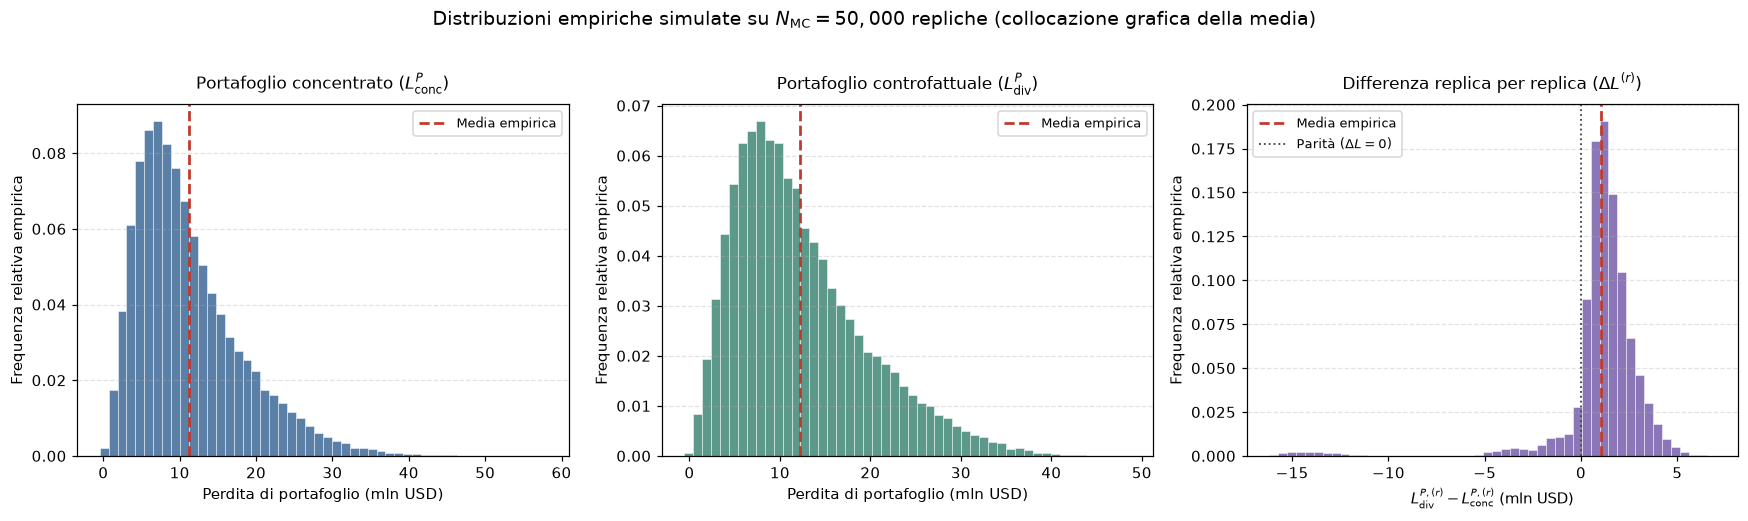

VERIFICA DEI CONTROLLI DELLA TAPPA 3
[Controllo 12] Coincidenza perdita totale con somma perdite individuali: True
   - Portafoglio concentrato (40 debitori): True | Max diff: 1.42e-14
   - Portafoglio controfattuale (39 debitori): True | Max diff: 1.42e-14
[Coerenza Passo 4] Tasso default == LGD (0.65): True | Identità tassi phi dei 39 debitori comuni: True


In [6]:
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DETERMINAZIONE DEI TASSI DI PERDITA MIGRATION-BASED phi(X_{i,0}, X_{i,4})
# ==============================================================================
# Indicizzazione vettoriale sulla matrice phi (righe = rating iniziale, colonne = rating finale)
phi_rate_conc = phi[X0_conc[None, :], X_T_conc]  # shape: (N_MC, 40)
phi_rate_div = phi[X0_div[None, :], X_T_div]     # shape: (N_MC, 39)

# ==============================================================================
# 2. CALCOLO DELLE PERDITE INDIVIDUALI E DI PORTAFOGLIO (IN MILIONI DI USD)
# ==============================================================================
# Perdite individuali per ciascuna replica r = 0, ..., N_MC - 1
L_ind_conc = V0_conc[None, :] * phi_rate_conc  # shape: (N_MC, 40)
L_ind_div = V0_div[None, :] * phi_rate_div     # shape: (N_MC, 39)

# Perdite complessive di portafoglio per replica (somma sulle posizioni)
L_conc = np.sum(L_ind_conc, axis=1)  # L_{conc}^{P,(r)}, shape: (N_MC,)
L_div = np.sum(L_ind_div, axis=1)    # L_{div}^{P,(r)},  shape: (N_MC,)

# Differenza replica per replica: Delta L^(r) = L_{div}^{P,(r)} - L_{conc}^{P,(r)}
Delta_L = L_div - L_conc             # shape: (N_MC,)

# ==============================================================================
# 3. RAPPRESENTAZIONE GRAFICA DELLE FREQUENZE EMPIRICHE SIMULATE
# ==============================================================================
# Nota: la linea verticale indica esclusivamente la collocazione grafica della media
# empirica, rimandando alla Tappa 4 la stima numerica esatta delle misure di sintesi.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), dpi=110)

serie_distribuzioni = [
    (
        axes[0],
        L_conc,
        "Portafoglio concentrato ($L_{\\mathrm{conc}}^P$)",
        "Perdita di portafoglio (mln USD)",
        "#2b5c8f"
    ),
    (
        axes[1],
        L_div,
        "Portafoglio controfattuale ($L_{\\mathrm{div}}^P$)",
        "Perdita di portafoglio (mln USD)",
        "#2e7d6b"
    ),
    (
        axes[2],
        Delta_L,
        "Differenza replica per replica ($\\Delta L^{(r)}$)",
        "$L_{\\mathrm{div}}^{P,(r)} - L_{\\mathrm{conc}}^{P,(r)}$ (mln USD)",
        "#6a51a3"
    )
]

for ax, dati, titolo, xlabel, colore in serie_distribuzioni:
    pesi_rel = np.ones_like(dati) / len(dati)
    ax.hist(
        dati,
        bins=50,
        weights=pesi_rel,
        color=colore,
        alpha=0.78,
        edgecolor="white",
        linewidth=0.4
    )
    # Posizione qualitativa della media senza esporre il valore numerico
    ax.axvline(
        np.mean(dati),
        color="#c0392b",
        linestyle="--",
        linewidth=1.8,
        label="Media empirica"
    )
    if titolo.startswith("Differenza"):
        ax.axvline(0.0, color="#444444", linestyle=":", linewidth=1.2, label="Parità ($\\Delta L = 0$)")

    ax.set_title(titolo, fontsize=11, pad=10)
    ax.set_xlabel(xlabel, fontsize=9.5)
    ax.set_ylabel("Frequenza relativa empirica", fontsize=9.5)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(frameon=True, fontsize=8.8)

fig.suptitle(
    f"Distribuzioni empiriche simulate su $N_{{\\mathrm{{MC}}}} = {N_MC:,}$ repliche (collocazione grafica della media)",
    fontsize=12.5,
    y=1.02
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. CONTROLLI NUMERICI E LOGICI DELLA TAPPA 3
# ==============================================================================
print("=" * 78)
print("VERIFICA DEI CONTROLLI DELLA TAPPA 3")
print("=" * 78)

# Controllo 12: La perdita totale di ciascun portafoglio coincide con la somma delle perdite individuali
somma_ind_conc = np.einsum("ri->r", L_ind_conc)
somma_ind_div = np.einsum("ri->r", L_ind_div)

max_err_conc = np.max(np.abs(L_conc - somma_ind_conc))
max_err_div = np.max(np.abs(L_div - somma_ind_div))

ctrl_12_conc = np.allclose(L_conc, somma_ind_conc, atol=1e-12) and (L_conc.shape == (N_MC,))
ctrl_12_div = np.allclose(L_div, somma_ind_div, atol=1e-12) and (L_div.shape == (N_MC,))
ctrl_12 = ctrl_12_conc and ctrl_12_div

assert ctrl_12, f"Controllo 12 fallito: max_err_conc={max_err_conc:.2e}, max_err_div={max_err_div:.2e}"
print(f"[Controllo 12] Coincidenza perdita totale con somma perdite individuali: {ctrl_12}")
print(f"   - Portafoglio concentrato (40 debitori): {ctrl_12_conc} | Max diff: {max_err_conc:.2e}")
print(f"   - Portafoglio controfattuale (39 debitori): {ctrl_12_div} | Max diff: {max_err_div:.2e}")

# Verifiche di coerenza strutturale della funzione di perdita migration-based (Passo 4):
# a) Per ogni debitore in default a t=4 (X_{i,4} = D), il tasso applicato è pari a LGD = 0.65
idx_D = rating_to_idx["D"]
mask_def_conc = (X_T_conc == idx_D)
lgd_ok = np.allclose(phi_rate_conc[mask_def_conc], LGD, atol=1e-12) if np.any(mask_def_conc) else True

# b) I 39 debitori comuni hanno identici tassi di perdita phi(X_{i,0}, X_{i,4}) nei due portafogli
phi_comuni_ok = np.allclose(phi_rate_conc[:, ~is_lehman], phi_rate_div, atol=1e-12)

assert lgd_ok and phi_comuni_ok, "Errore di coerenza nell'applicazione della mappa phi."
print(f"[Coerenza Passo 4] Tasso default == LGD ({LGD}): {lgd_ok} | Identità tassi phi dei 39 debitori comuni: {phi_comuni_ok}")
print("=" * 78)

## Tappa 4 — Stima delle misure di sintesi, rischio di coda e confronto tra portafogli

### Richiesta dello studente

> Sto lavorando sulla Tappa 4

---

### Sintesi logica della Tappa 4

- **Input:**
  - Distribuzioni empiriche simulate nella **Tappa 3**, espresse in milioni di dollari su $N_{\mathrm{MC}} = 50\,000$ repliche:
    - `L_conc`: perdite del portafoglio iniziale concentrato ($L_{\mathrm{conc}}^{P,(r)}$);
    - `L_div`: perdite del portafoglio controfattuale con riallocazione proporzionale ($L_{\mathrm{div}}^{P,(r)}$);
    - `Delta_L`: differenza replica per replica ($\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$).
  - Esposizione complessiva iniziale $V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$ milioni di dollari (dalla **Tappa 1**) per la verifica dell'unità monetaria delle misure di rischio.

- **Operazioni:**
  - Calcolo delle misure di sintesi e dispersione sulle distribuzioni empiriche delle perdite monetarie (in milioni di USD) per entrambi i portafogli:
    - perdita media campionaria $\widehat{\mathbb{E}}[L^P] = \frac{1}{N_{\mathrm{MC}}} \sum_{r=1}^{N_{\mathrm{MC}}} L^{P,(r)}$;
    - varianza campionaria $\widehat{\operatorname{Var}}(L^P) = \frac{1}{N_{\mathrm{MC}} - 1} \sum_{r=1}^{N_{\mathrm{MC}}} \left(L^{P,(r)} - \widehat{\mathbb{E}}[L^P]\right)^2$;
    - deviazione standard campionaria $\widehat{\sigma}(L^P) = \sqrt{\widehat{\operatorname{Var}}(L^P)}$.
  - Calcolo delle misure di rischio di coda ai livelli di confidenza $\alpha \in \{0.95, 0.99\}$ sulle distribuzioni empiriche delle perdite monetarie (in milioni di USD):
    - Value at Risk empirico $\widehat{\operatorname{VaR}}_\alpha(L^P) = F_{L^P, N_{\mathrm{MC}}}^{-1}(\alpha)$;
    - Conditional Value at Risk empirico secondo la definizione tramite quantili:
      $$\widehat{\operatorname{CVaR}}_\alpha(L^P) = \frac{1}{1 - \alpha} \int_\alpha^1 \widehat{\operatorname{VaR}}_u(L^P)\,du = \frac{1}{(1 - \alpha) N_{\mathrm{MC}}} \sum_{k = \alpha N_{\mathrm{MC}} + 1}^{N_{\mathrm{MC}}} L_{(k)}^P$$
  - Calcolo della variazione per ciascuna misura di rischio $\rho$ tra portafoglio controfattuale e portafoglio concentrato:
    $$\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$$
  - Costruzione della **Tabella 3 — Misure di rischio** e sintesi numerica della distribuzione empirica di $\Delta L^{(r)}$.
  - Esecuzione del controllo numerico sulla scala monetaria e sulla coerenza delle stime di VaR e CVaR (`Controllo 14`).

- **Output:**
  - Dizionari e variabili scalari delle misure stimate in memoria (`risk_conc`, `risk_div`, `delta_risk`, `var_95_conc`, `var_99_conc`, `cvar_95_conc`, `cvar_99_conc`, `var_95_div`, `var_99_div`, `cvar_95_div`, `cvar_99_div`).
  - **Tabella 3 — Misure di rischio** (confronto tra portafoglio concentrato, portafoglio con riallocazione proporzionale e differenza $\Delta\rho$).
  - Tabella di sintesi numerica della distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.
  - Esito esplicito del `Controllo 14`.

- **Controlli della tappa:**
  - **Controllo 14:** Verifica che VaR e CVaR siano calcolati sulle distribuzioni empiriche delle perdite monetarie, espresse in milioni di dollari (verificando l'assenza di normalizzazioni percentuali/relative, l'appartenenza al supporto monetario simulato e le disuguaglianze strutturali tra quantili e CVaR).

- **Uso successivo:**
  - Le soglie `var_95_conc` e `var_99_conc` costituiscono l'input diretto della **Tappa 6** per l'indicazione grafica dei livelli VaR nella **Figura 1**.
  - Le stime di perdita attesa, deviazione standard, VaR e CVaR di entrambi i portafogli costituiscono il riferimento numerico per la verifica di stabilità al crescere di $N_{\mathrm{MC}}$ nella **Tappa 6** (`Controllo 15`).
  - La **Tabella 3** e la sintesi distributiva di $\Delta L^{(r)}$ confluiscono negli output tabellari e numerici del prodotto finale.

In [7]:
# ==============================================================================
# 1. FUNZIONI DI STIMA EMPIRICA DELLE MISURE DI SINTESI E DI RISCHIO DI CODA
# ==============================================================================
def calcola_var_empirico(perdite: np.ndarray, alpha: float) -> float:
    """
    Calcola il Value at Risk empirico al livello alpha sulla distribuzione
    delle perdite monetarie (in milioni di USD).
    """
    return float(np.quantile(perdite, alpha))


def calcola_cvar_empirico(perdite: np.ndarray, alpha: float) -> float:
    """
    Calcola il Conditional Value at Risk empirico al livello alpha secondo la
    definizione mediante quantili:
        CVaR_alpha(L) = 1 / (1 - alpha) * int_alpha^1 VaR_u(L) du
    valutata esattamente sulle statistiche d'ordine superiori del campione simulato.
    """
    n = len(perdite)
    perdite_ordinate = np.sort(perdite)
    idx_inizio = int(np.ceil(alpha * n))
    return float(np.mean(perdite_ordinate[idx_inizio:]))


def calcola_misure_portafoglio(perdite: np.ndarray) -> dict:
    """
    Restituisce il dizionario completo delle misure di sintesi e di rischio
    (in milioni di USD) per un vettore di perdite simulate.
    """
    media = float(np.mean(perdite))
    varianza = float(np.var(perdite, ddof=1))
    dev_std = float(np.std(perdite, ddof=1))
    var_95 = calcola_var_empirico(perdite, 0.95)
    cvar_95 = calcola_cvar_empirico(perdite, 0.95)
    var_99 = calcola_var_empirico(perdite, 0.99)
    cvar_99 = calcola_cvar_empirico(perdite, 0.99)

    return {
        "Perdita media E[L^P]": media,
        "Varianza Var(L^P)": varianza,
        "Deviazione standard": dev_std,
        "VaR 95%": var_95,
        "CVaR 95%": cvar_95,
        "VaR 99%": var_99,
        "CVaR 99%": cvar_99,
    }


# ==============================================================================
# 2. STIMA DELLE MISURE DI RISCHIO E DELLE DIFFERENZE DELTA_RHO
# ==============================================================================
risk_conc = calcola_misure_portafoglio(L_conc)
risk_div = calcola_misure_portafoglio(L_div)

# Variazione per ciascuna misura di rischio: Delta rho = rho(L_div^P) - rho(L_conc^P)
delta_risk = {
    misura: risk_div[misura] - risk_conc[misura]
    for misura in risk_conc
}

# Esposizione esplicita delle soglie VaR e CVaR in memoria per le tappe successive
var_95_conc = risk_conc["VaR 95%"]
cvar_95_conc = risk_conc["CVaR 95%"]
var_99_conc = risk_conc["VaR 99%"]
cvar_99_conc = risk_conc["CVaR 99%"]

var_95_div = risk_div["VaR 95%"]
cvar_95_div = risk_div["CVaR 95%"]
var_99_div = risk_div["VaR 99%"]
cvar_99_div = risk_div["CVaR 99%"]

# ==============================================================================
# 3. PRODUZIONE TABELLA 3 — MISURE DI RISCHIO
# ==============================================================================
unita_misure = [
    "mln USD",
    "(mln USD)^2",
    "mln USD",
    "mln USD",
    "mln USD",
    "mln USD",
    "mln USD",
]

righe_tab3 = []
for (misura, val_conc), unita in zip(risk_conc.items(), unita_misure):
    val_div = risk_div[misura]
    diff = delta_risk[misura]
    var_pct = (diff / val_conc * 100.0) if abs(val_conc) > 1e-12 else np.nan
    righe_tab3.append({
        "Misura di rischio": misura,
        "Unità": unita,
        "Portafoglio concentrato": val_conc,
        "Portafoglio controfattuale": val_div,
        "Differenza (Div - Conc)": diff,
        "Variazione (%)": var_pct,
    })

tabella_3 = pd.DataFrame(righe_tab3)

display(Markdown("### Tabella 3 — Misure di rischio (portafoglio concentrato vs. portafoglio controfattuale)"))
display(tabella_3.style.format({
    "Portafoglio concentrato": "{:.4f}",
    "Portafoglio controfattuale": "{:.4f}",
    "Differenza (Div - Conc)": "{:+.4f}",
    "Variazione (%)": "{:+.2f}%"
}).hide(axis="index"))

# ==============================================================================
# 4. SINTESI NUMERICA DELLA DISTRIBUZIONE EMPIRICA DI DELTA L^(r)
# ==============================================================================
sintesi_delta_L = pd.DataFrame([
    {"Statistica": "Media campionaria E[Delta L]",        "Valore (mln USD)": float(np.mean(Delta_L))},
    {"Statistica": "Varianza campionaria Var(Delta L)",    "Valore (mln USD)": float(np.var(Delta_L, ddof=1))},
    {"Statistica": "Deviazione standard sigma(Delta L)",   "Valore (mln USD)": float(np.std(Delta_L, ddof=1))},
    {"Statistica": "Minimo osservato",                     "Valore (mln USD)": float(np.min(Delta_L))},
    {"Statistica": "Percentile 1% (q_0.01)",               "Valore (mln USD)": float(np.quantile(Delta_L, 0.01))},
    {"Statistica": "Percentile 5% (q_0.05)",               "Valore (mln USD)": float(np.quantile(Delta_L, 0.05))},
    {"Statistica": "Primo quartile (q_0.25)",              "Valore (mln USD)": float(np.quantile(Delta_L, 0.25))},
    {"Statistica": "Mediana (q_0.50)",                     "Valore (mln USD)": float(np.quantile(Delta_L, 0.50))},
    {"Statistica": "Terzo quartile (q_0.75)",              "Valore (mln USD)": float(np.quantile(Delta_L, 0.75))},
    {"Statistica": "Percentile 95% (q_0.95)",              "Valore (mln USD)": float(np.quantile(Delta_L, 0.95))},
    {"Statistica": "Percentile 99% (q_0.99)",              "Valore (mln USD)": float(np.quantile(Delta_L, 0.99))},
    {"Statistica": "Massimo osservato",                    "Valore (mln USD)": float(np.max(Delta_L))},
])

display(Markdown("### Sintesi numerica della distribuzione empirica di $\\Delta L^{(r)} = L_{\\mathrm{div}}^{P,(r)} - L_{\\mathrm{conc}}^{P,(r)}$"))
display(sintesi_delta_L.style.format({
    "Valore (mln USD)": "{:+.4f}"
}).hide(axis="index"))

# ==============================================================================
# 5. CONTROLLI NUMERICI DELLA TAPPA 4
# ==============================================================================
print("=" * 78)
print("VERIFICA DEI CONTROLLI DELLA TAPPA 4")
print("=" * 78)

# Controllo 14: VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite
# monetarie espresse in milioni di dollari
# 1) Verifica monetaria: le perdite sono espresse in mln USD (scala coerente con V_0^P = 173 mln USD
#    e con la somma delle perdite individuali V_{i,0} * phi, non normalizzate su [0, 1])
scala_monetaria_conc = np.allclose(L_conc, np.sum(L_ind_conc, axis=1), atol=1e-12) and (np.max(L_conc) > 1.0)
scala_monetaria_div = np.allclose(L_div, np.sum(L_ind_div, axis=1), atol=1e-12) and (np.max(L_div) > 1.0)

# 2) Verifica di coerenza ordinale e appartenenza al supporto monetario per entrambi i portafogli
coerenza_conc = (
    (np.min(L_conc) <= var_95_conc <= cvar_95_conc <= np.max(L_conc))
    and (np.min(L_conc) <= var_99_conc <= cvar_99_conc <= np.max(L_conc))
    and (var_95_conc <= var_99_conc)
    and (cvar_95_conc <= cvar_99_conc)
)
coerenza_div = (
    (np.min(L_div) <= var_95_div <= cvar_95_div <= np.max(L_div))
    and (np.min(L_div) <= var_99_div <= cvar_99_div <= np.max(L_div))
    and (var_95_div <= var_99_div)
    and (cvar_95_div <= cvar_99_div)
)

# 3) Verifica dell'identità della variazione Delta rho = rho(L_div) - rho(L_conc)
coerenza_delta = all(
    np.isclose(delta_risk[k], risk_div[k] - risk_conc[k], atol=1e-12)
    for k in risk_conc
)

ctrl_14 = scala_monetaria_conc and scala_monetaria_div and coerenza_conc and coerenza_div and coerenza_delta
assert ctrl_14, "Controllo 14 fallito: incoerenza nella scala monetaria o nei quantili empirici."

print(f"[Controllo 14] VaR e CVaR calcolati su perdite monetarie empiriche (mln USD): {ctrl_14}")
print(f"   - Concentrato:    VaR_95 = {var_95_conc:.4f} <= CVaR_95 = {cvar_95_conc:.4f} | VaR_99 = {var_99_conc:.4f} <= CVaR_99 = {cvar_99_conc:.4f} mln USD")
print(f"   - Controfattuale: VaR_95 = {var_95_div:.4f} <= CVaR_95 = {cvar_95_div:.4f} | VaR_99 = {var_99_div:.4f} <= CVaR_99 = {cvar_99_div:.4f} mln USD")
print("=" * 78)

### Tabella 3 — Misure di rischio (portafoglio concentrato vs. portafoglio controfattuale)

Misura di rischio,Unità,Portafoglio concentrato,Portafoglio controfattuale,Differenza (Div - Conc),Variazione (%)
Perdita media E[L^P],mln USD,11.1896,12.2547,+1.0651,+9.52%
Varianza Var(L^P),(mln USD)^2,48.4928,53.3975,+4.9048,+10.11%
Deviazione standard,mln USD,6.9637,7.3074,+0.3437,+4.94%
VaR 95%,mln USD,24.9800,26.7566,+1.7766,+7.11%
CVaR 95%,mln USD,29.7866,31.0223,+1.2356,+4.15%
VaR 99%,mln USD,32.8002,33.7701,+0.9699,+2.96%
CVaR 99%,mln USD,37.1532,36.9149,-0.2383,-0.64%


### Sintesi numerica della distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$

Statistica,Valore (mln USD)
Media campionaria E[Delta L],+1.0651
Varianza campionaria Var(Delta L),+5.7411
Deviazione standard sigma(Delta L),+2.3961
Minimo osservato,-16.1959
Percentile 1% (q_0.01),-13.6791
Percentile 5% (q_0.05),-1.5861
Primo quartile (q_0.25),+0.6605
Mediana (q_0.50),+1.2601
Terzo quartile (q_0.75),+2.0236
Percentile 95% (q_0.95),+3.5084


VERIFICA DEI CONTROLLI DELLA TAPPA 4
[Controllo 14] VaR e CVaR calcolati su perdite monetarie empiriche (mln USD): True
   - Concentrato:    VaR_95 = 24.9800 <= CVaR_95 = 29.7866 | VaR_99 = 32.8002 <= CVaR_99 = 37.1532 mln USD
   - Controfattuale: VaR_95 = 26.7566 <= CVaR_95 = 31.0223 | VaR_99 = 33.7701 <= CVaR_99 = 36.9149 mln USD


## Tappa 5 — Analisi condizionata all'ingresso nel regime di crisi $C$

### Richiesta dello studente

> Sto lavorando sulla Tappa 5

---

### Sintesi logica della Tappa 5

- **Input:**
  - Vettore delle perdite simulate del portafoglio iniziale concentrato `L_conc` ($L_{\mathrm{conc}}^{P,(r)}$, in milioni di USD) generato nella **Tappa 3**.
  - Indicatore booleano di ingresso nel regime di crisi `in_regime_C` ($E_C^{(r)} = \mathbb{I}\{\exists t \in \{0, 1, 2, 3\} : M_t^{(r)} = C\}$) e traiettorie sistemiche `M_paths` generati nella **Tappa 2**.
  - Matrice di transizione del regime sistemico $Q$, stato iniziale $M_0 = S$ e mappatura degli stati (`REGIME_STATES`, `regime_to_idx`) validati nella **Tappa 1**, unitamente alla perdita media incondizionata $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$ calcolata nella **Tappa 4**.

- **Operazioni:**
  - Stima della probabilità empirica che il regime sistemico raggiunga lo stato di crisi $C$ almeno una volta durante l'orizzonte trimestrale $t \in \{0, 1, 2, 3\}$:
    $$\widehat{\mathbb{P}}(E_C) = \frac{1}{N_{\mathrm{MC}}} \sum_{r=1}^{N_{\mathrm{MC}}} \mathbb{I}_{E_C^{(r)}}$$
  - Partizione delle $N_{\mathrm{MC}} = 50\,000$ repliche di $L_{\mathrm{conc}}^{P,(r)}$ nei due sottocampioni disgiunti:
    - repliche con ingresso almeno una volta nel regime $C$ ($E_C^{(r)} = 1$);
    - repliche senza mai ingresso nel regime $C$ ($E_C^{(r)} = 0$).
  - Calcolo delle perdite medie condizionate del portafoglio concentrato nei due regimi campionari:
    $$\widehat{\mathbb{E}}\left[L_{\mathrm{conc}}^P \mid E_C\right] = \frac{1}{N_C} \sum_{r : E_C^{(r)} = 1} L_{\mathrm{conc}}^{P,(r)}, \qquad \widehat{\mathbb{E}}\left[L_{\mathrm{conc}}^P \mid E_C^c\right] = \frac{1}{N_{\neg C}} \sum_{r : E_C^{(r)} = 0} L_{\mathrm{conc}}^{P,(r)}$$
  - Costruzione della **Tabella 4 — Regime sistemico e perdita** per il confronto tra repliche con e senza ingresso nello stato $C$.
  - Esecuzione dei controlli di partizione completa del campione, di ricomposizione tramite legge delle aspettative totali e di coerenza markoviana tra la frequenza simulata $\widehat{\mathbb{P}}(E_C)$ e la probabilità teorica derivabile dalla matrice $Q$.

- **Output:**
  - `prob_regime_C`: probabilità simulata che il regime $C$ venga raggiunto almeno una volta durante l'orizzonte.
  - `L_conc_in_C` e `L_conc_no_C`: sottocampioni delle perdite simulate del portafoglio concentrato nelle repliche con e senza ingresso nello stato $C$ (in milioni di USD).
  - `mean_L_conc_in_C` e `mean_L_conc_no_C`: perdite medie condizionate del portafoglio concentrato nei due sottocampioni (in milioni di USD).
  - **Tabella 4 — Regime sistemico e perdita** (confronto, per il portafoglio concentrato, tra repliche con e senza ingresso nello stato $C$).
  - Esito esplicito dei controlli della tappa.

- **Controlli della tappa:**
  - Verifica di partizione completa del campione simulato ($N_C + N_{\neg C} = N_{\mathrm{MC}}$).
  - Verifica della legge delle aspettative totali ($\widehat{\mathbb{P}}(E_C)\,\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C] + (1 - \widehat{\mathbb{P}}(E_C))\,\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid E_C^c] = \widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$).
  - Controllo integrativo di coerenza markoviana tra la probabilità simulata $\widehat{\mathbb{P}}(E_C)$ e la probabilità teorica esatta $\mathbb{P}_{\mathrm{teor}}(E_C) = 1 - \mathbf{e}_S^\top \tilde{Q}^{3} \mathbf{1}_2$ ottenuta dalla catena di Markov $Q$.

- **Uso successivo:**
  - I due sottocampioni condizionati `L_conc_in_C` e `L_conc_no_C` e le rispettive perdite medie condizionate `mean_L_conc_in_C` e `mean_L_conc_no_C` costituiscono l'input diretto della **Tappa 6** per la costruzione della **Figura 3 — Regime sistemico e perdita**.
  - La probabilità simulata `prob_regime_C`, le perdite medie condizionate e la **Tabella 4** confluiscono negli output numerici e tabellari del prodotto finale.

In [8]:
# ==============================================================================
# 1. PARTIZIONE DEL CAMPIONE IN BASE ALL'INGRESSO NEL REGIME DI CRISI C
# ==============================================================================
# Evento E_C = {esiste t in {0, 1, 2, 3} tale che M_t = C}
L_conc_in_C = L_conc[in_regime_C]     # Repliche con ingresso almeno una volta in C
L_conc_no_C = L_conc[~in_regime_C]    # Repliche senza mai ingresso in C

n_in_C = int(L_conc_in_C.size)
n_no_C = int(L_conc_no_C.size)

# Probabilità empiriche simulate
prob_regime_C = float(np.mean(in_regime_C))
prob_no_regime_C = float(np.mean(~in_regime_C))

# Perdite medie condizionate del portafoglio concentrato (in milioni di USD)
mean_L_conc_in_C = float(np.mean(L_conc_in_C))
mean_L_conc_no_C = float(np.mean(L_conc_no_C))
diff_mean_C = mean_L_conc_in_C - mean_L_conc_no_C

# Statistiche descrittive condizionate di supporto
std_L_conc_in_C = float(np.std(L_conc_in_C, ddof=1))
std_L_conc_no_C = float(np.std(L_conc_no_C, ddof=1))
med_L_conc_in_C = float(np.median(L_conc_in_C))
med_L_conc_no_C = float(np.median(L_conc_no_C))

# ==============================================================================
# 2. STIMA PUNTUALE DI P(E_C) E PRODUZIONE TABELLA 4 — REGIME SISTEMICO E PERDITA
# ==============================================================================
display(Markdown(
    f"### Probabilità simulata di ingresso almeno una volta nel regime $C$\n\n"
    f"- **Probabilità empirica $\\widehat{{\\mathbb{{P}}}}(E_C)$:** `{prob_regime_C:.6f}` (`{prob_regime_C * 100:.2f}%`, pari a `{n_in_C:,}` repliche su `{N_MC:,}`)\n"
    f"- **Probabilità complementare $\\widehat{{\\mathbb{{P}}}}(E_C^c)$:** `{prob_no_regime_C:.6f}` (`{prob_no_regime_C * 100:.2f}%`, pari a `{n_no_C:,}` repliche su `{N_MC:,}`)"
))

tabella_4 = pd.DataFrame([
    {
        "Indicatore": "Numero di repliche",
        "Unità": "conteggio",
        "Con ingresso in C (E_C)": f"{n_in_C:,}",
        "Senza ingresso in C (E_C^c)": f"{n_no_C:,}",
        "Differenza (Con C - Senza C)": f"{n_in_C - n_no_C:+,}"
    },
    {
        "Indicatore": "Frequenza relativa / Probabilità",
        "Unità": "%",
        "Con ingresso in C (E_C)": f"{prob_regime_C * 100:.2f}%",
        "Senza ingresso in C (E_C^c)": f"{prob_no_regime_C * 100:.2f}%",
        "Differenza (Con C - Senza C)": f"{(prob_regime_C - prob_no_regime_C) * 100:+.2f}%"
    },
    {
        "Indicatore": "Perdita media condizionata E[L_conc^P | .]",
        "Unità": "mln USD",
        "Con ingresso in C (E_C)": f"{mean_L_conc_in_C:.4f}",
        "Senza ingresso in C (E_C^c)": f"{mean_L_conc_no_C:.4f}",
        "Differenza (Con C - Senza C)": f"{diff_mean_C:+.4f}"
    },
    {
        "Indicatore": "Deviazione standard condizionata",
        "Unità": "mln USD",
        "Con ingresso in C (E_C)": f"{std_L_conc_in_C:.4f}",
        "Senza ingresso in C (E_C^c)": f"{std_L_conc_no_C:.4f}",
        "Differenza (Con C - Senza C)": f"{std_L_conc_in_C - std_L_conc_no_C:+.4f}"
    },
    {
        "Indicatore": "Mediana condizionata",
        "Unità": "mln USD",
        "Con ingresso in C (E_C)": f"{med_L_conc_in_C:.4f}",
        "Senza ingresso in C (E_C^c)": f"{med_L_conc_no_C:.4f}",
        "Differenza (Con C - Senza C)": f"{med_L_conc_in_C - med_L_conc_no_C:+.4f}"
    }
])

display(Markdown("### Tabella 4 — Regime sistemico e perdita (portafoglio concentrato)"))
display(tabella_4.style.hide(axis="index"))

# ==============================================================================
# 3. CONTROLLI NUMERICI E INTEGRATIVI DELLA TAPPA 5
# ==============================================================================
print("=" * 78)
print("VERIFICA DEI CONTROLLI DELLA TAPPA 5")
print("=" * 78)

# 1) Verifica di partizione completa ed esclusiva delle repliche Monte Carlo
partizione_ok = (n_in_C + n_no_C == N_MC) and np.isclose(prob_regime_C + prob_no_regime_C, 1.0, atol=1e-15)
assert partizione_ok, f"Partizione incompleta: n_in_C={n_in_C}, n_no_C={n_no_C}, N_MC={N_MC}"
print(f"[Controllo Partizione] n_in_C + n_no_C == N_MC ({N_MC:,}): {partizione_ok}")

# 2) Verifica della Legge delle Aspettative Totali sulla perdita media del portafoglio concentrato
media_ricomposta = prob_regime_C * mean_L_conc_in_C + prob_no_regime_C * mean_L_conc_no_C
media_incondizionata = risk_conc["Perdita media E[L^P]"]
err_ricomposizione = abs(media_ricomposta - media_incondizionata)
aspettative_totali_ok = np.isclose(media_ricomposta, media_incondizionata, atol=1e-12)
assert aspettative_totali_ok, f"Errore legge aspettative totali: diff={err_ricomposizione:.2e}"
print(f"[Controllo Aspettative Totali] Ricomposizione esatta di E[L_conc^P]: {aspettative_totali_ok} (diff: {err_ricomposizione:.2e})")

# 3) Controllo integrativo di coerenza markoviana: confronto tra probabilità simulata
#    e probabilità teorica esatta di raggiungere lo stato C almeno una volta da M_0 = S
idx_non_C = [regime_to_idx["O"], regime_to_idx["S"]]
Q_non_C = Q[np.ix_(idx_non_C, idx_non_C)]  # Sottomatrice 2x2 degli stati {O, S}
# Distribuzione iniziale su {O, S} a t = 0 dato M_0 = S
p0_non_C = np.array([1.0 if idx == M0_idx else 0.0 for idx in idx_non_C], dtype=float)
# Probabilità di restare sempre in {O, S} per t = 0, 1, 2, 3 (cioè per T - 1 = 3 passi)
prob_never_C_teor = float(p0_non_C @ np.linalg.matrix_power(Q_non_C, T - 1) @ np.ones(len(idx_non_C)))
prob_regime_C_teor = 1.0 - prob_never_C_teor

errore_std_mc = np.sqrt(prob_regime_C_teor * (1.0 - prob_regime_C_teor) / N_MC)
scarto_prob = abs(prob_regime_C - prob_regime_C_teor)
coerenza_markov_ok = scarto_prob < 4.0 * errore_std_mc
assert coerenza_markov_ok, (
    f"Scarto eccessivo tra P(E_C) simulata ({prob_regime_C:.5f}) e teorica ({prob_regime_C_teor:.5f})"
)

print(f"[Controllo Integrativo Markov] Coerenza tra P(E_C) simulata e teorica: {coerenza_markov_ok}")
print(f"   - P(E_C) simulata : {prob_regime_C:.6f} ({prob_regime_C * 100:.2f}%)")
print(f"   - P(E_C) teorica  : {prob_regime_C_teor:.6f} ({prob_regime_C_teor * 100:.2f}%)")
print(f"   - Scarto assoluto : {scarto_prob:.6f} (soglia 4*SE = {4.0 * errore_std_mc:.6f})")
print("=" * 78)

### Probabilità simulata di ingresso almeno una volta nel regime $C$

- **Probabilità empirica $\widehat{\mathbb{P}}(E_C)$:** `0.300780` (`30.08%`, pari a `15,039` repliche su `50,000`)
- **Probabilità complementare $\widehat{\mathbb{P}}(E_C^c)$:** `0.699220` (`69.92%`, pari a `34,961` repliche su `50,000`)

### Tabella 4 — Regime sistemico e perdita (portafoglio concentrato)

Indicatore,Unità,Con ingresso in C (E_C),Senza ingresso in C (E_C^c),Differenza (Con C - Senza C)
Numero di repliche,conteggio,"15,039","34,961","-19,922"
Frequenza relativa / Probabilità,%,30.08%,69.92%,-39.84%
Perdita media condizionata E[L_conc^P | .],mln USD,18.3842,8.0947,+10.2895
Deviazione standard condizionata,mln USD,6.7745,4.2150,+2.5595
Mediana condizionata,mln USD,17.6200,7.5100,+10.1100


VERIFICA DEI CONTROLLI DELLA TAPPA 5
[Controllo Partizione] n_in_C + n_no_C == N_MC (50,000): True
[Controllo Aspettative Totali] Ricomposizione esatta di E[L_conc^P]: True (diff: 3.55e-15)
[Controllo Integrativo Markov] Coerenza tra P(E_C) simulata e teorica: True
   - P(E_C) simulata : 0.300780 (30.08%)
   - P(E_C) teorica  : 0.299295 (29.93%)
   - Scarto assoluto : 0.001485 (soglia 4*SE = 0.008192)


## Tappa 6 — Produzione dei grafici diagnostici e verifica di stabilità Monte Carlo

### Richiesta dello studente

> Sto lavorando sulla Tappa 6

---

### Sintesi logica della Tappa 6

- **Input:**
  - Distribuzioni empiriche simulate nella **Tappa 3**, espresse in milioni di dollari su $N_{\mathrm{MC}} = 50\,000$ repliche: `L_conc` ($L_{\mathrm{conc}}^{P,(r)}$) e `L_div` ($L_{\mathrm{div}}^{P,(r)}$).
  - Soglie empiriche del Value at Risk e misure di rischio stimate nella **Tappa 4**: `var_95_conc`, `var_99_conc`, `var_95_div`, `var_99_div`, `risk_conc`, `risk_div`, unitamente alle funzioni `calcola_var_empirico` e `calcola_cvar_empirico`.
  - Sottocampioni condizionati all'ingresso nel regime di crisi $C$ e relative medie condizionate calcolati nella **Tappa 5**: `L_conc_in_C`, `L_conc_no_C`, `mean_L_conc_in_C`, `mean_L_conc_no_C`, `n_in_C`, `n_no_C`, `prob_regime_C`, `prob_no_regime_C`.

- **Operazioni:**
  - Costruzione della **Figura 1 — Distribuzione della perdita del portafoglio concentrato**, rappresentando l'istogramma delle frequenze relative empiriche di $L_{\mathrm{conc}}^P$ con l'indicazione verticale delle soglie $\operatorname{VaR}_{0.95}(L_{\mathrm{conc}}^P)$ e $\operatorname{VaR}_{0.99}(L_{\mathrm{conc}}^P)$.
  - Costruzione della **Figura 2 — Confronto delle distribuzioni**, affiancando il confronto sull'intero supporto tra le distribuzioni empiriche di $L_{\mathrm{conc}}^P$ e $L_{\mathrm{div}}^P$ e un ingrandimento dedicato alla coda destra (oltre il $90^\circ$ percentile), con evidenza dei rispettivi livelli $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$.
  - Costruzione della **Figura 3 — Regime sistemico e perdita**, confrontando la distribuzione empirica (istogramma normalizzato e boxplot) delle perdite del portafoglio concentrato nelle repliche in cui lo stato $C$ viene raggiunto almeno una volta ($E_C$) rispetto alle repliche in cui non viene mai raggiunto ($E_C^c$), con indicazione delle rispettive medie condizionate.
  - Valutazione delle stime progressive delle principali misure di rischio ($\widehat{\mathbb{E}}[L^P]$, deviazione standard, $\widehat{\operatorname{VaR}}_{0.95}$, $\widehat{\operatorname{CVaR}}_{0.95}$, $\widehat{\operatorname{VaR}}_{0.99}$, $\widehat{\operatorname{CVaR}}_{0.99}$) su sottocampioni iniziali crescenti $n \le N_{\mathrm{MC}}$ per verificare la stabilità campionaria al crescere delle repliche (`Controllo 15`).

- **Output:**
  - **Figura 1 — Distribuzione della perdita del portafoglio concentrato**.
  - **Figura 2 — Confronto delle distribuzioni**.
  - **Figura 3 — Regime sistemico e perdita**.
  - Tabella e grafico diagnostico di convergenza delle misure di rischio al crescere del numero di repliche simulate, ed esito esplicito del `Controllo 15`.

- **Controlli della tappa:**
  - **Controllo 15:** Verifica che le principali misure di rischio mostrino una ragionevole stabilità al crescere del numero di repliche simulate.

- **Uso successivo:**
  - Completa tutti gli output grafici e tutti i controlli richiesti dalla Scheda Caso nel notebook, rendendo disponibili i risultati numerici, tabellari e grafici per la formulazione autonoma dell'interpretazione critica conclusiva da parte dello studente (**Fase 8**).

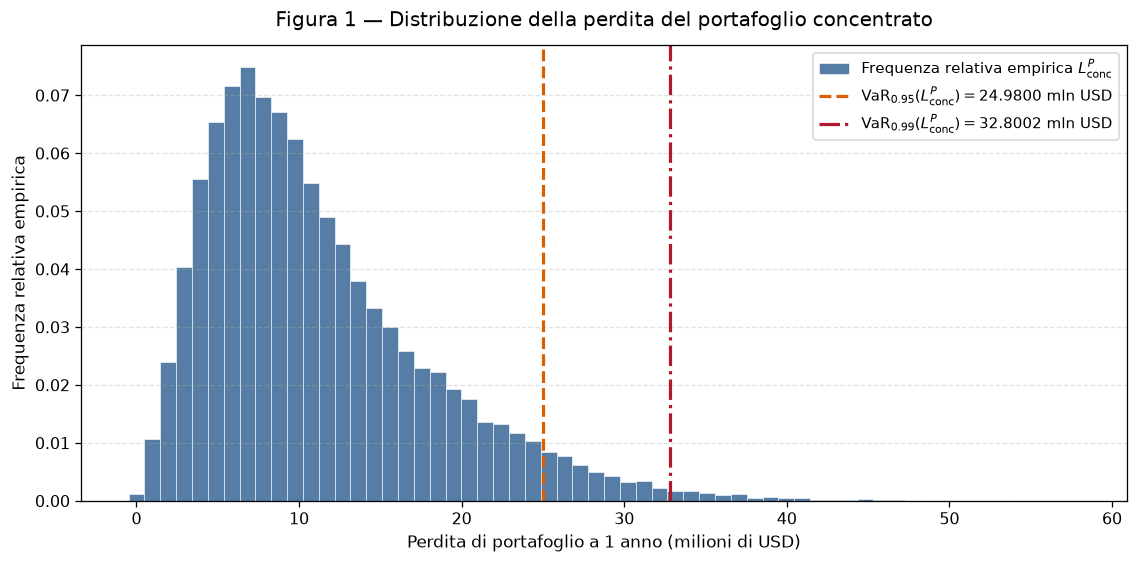

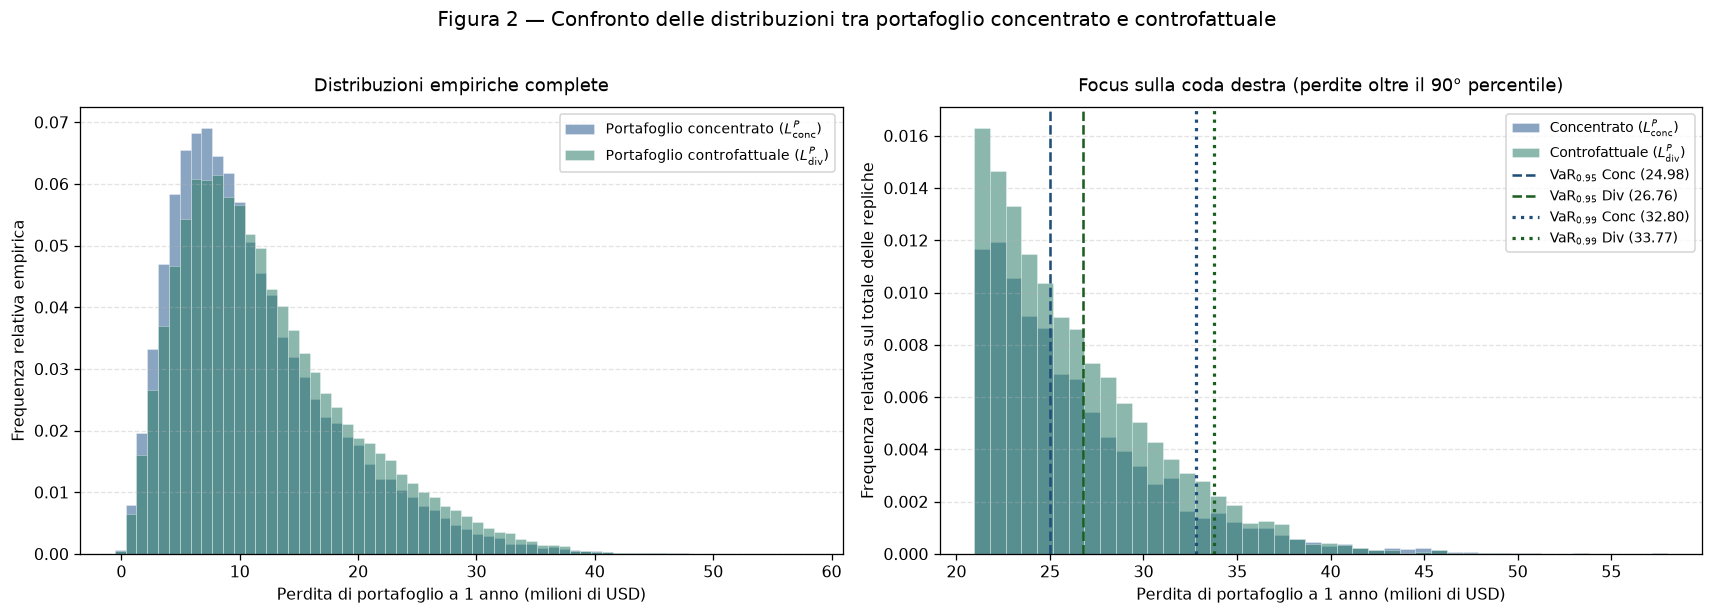

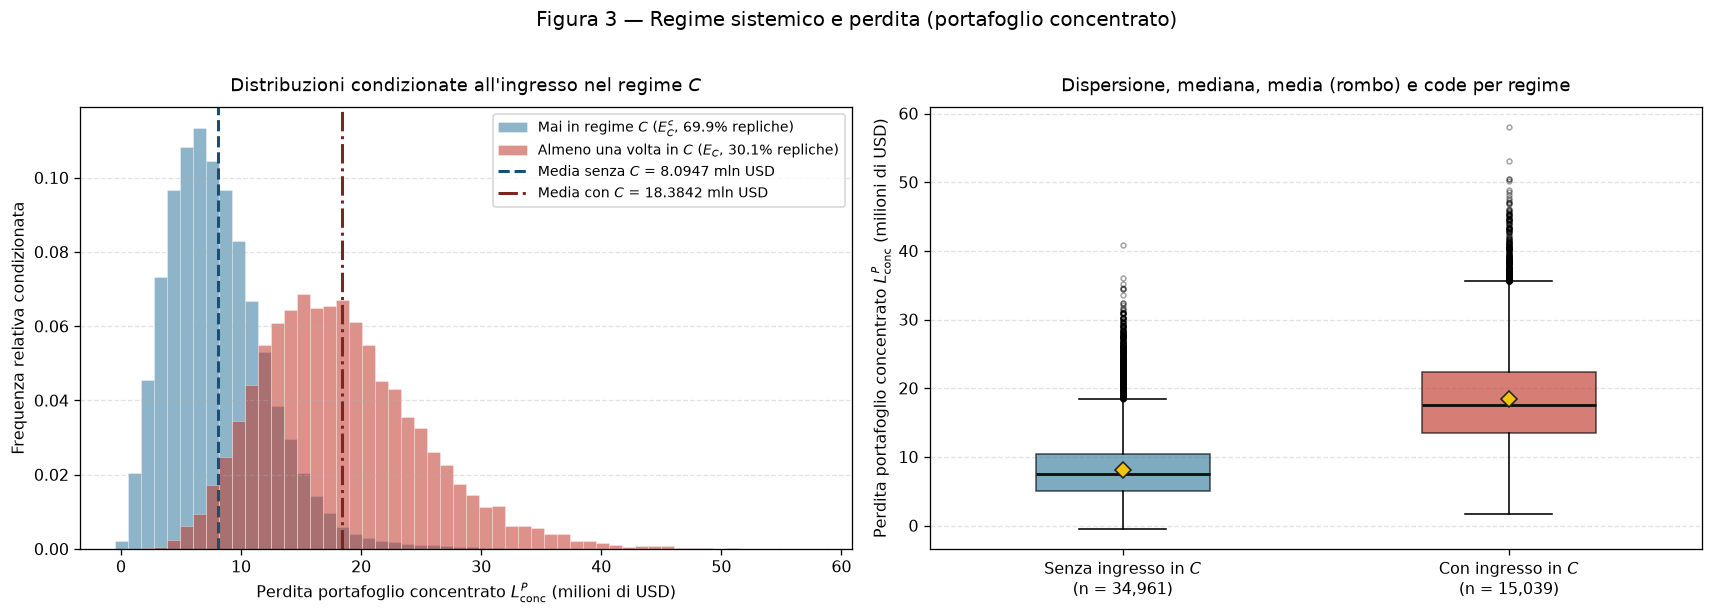

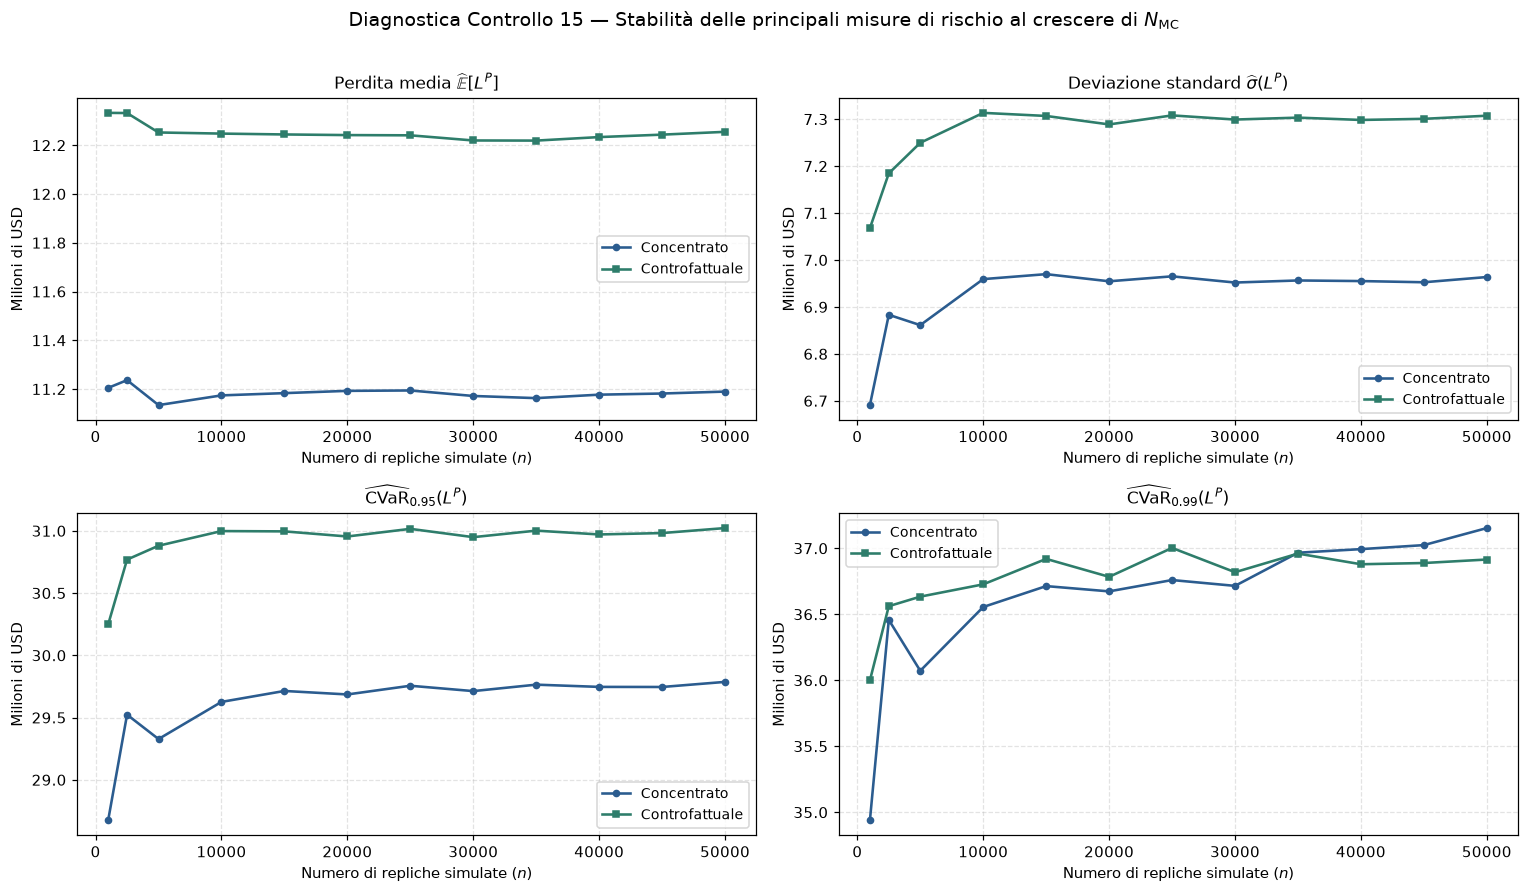

### Tabella diagnostica — Andamento delle misure di rischio al crescere delle repliche

Portafoglio,N_repliche,Media,Dev_std,VaR_95,CVaR_95,VaR_99,CVaR_99
Concentrato,"5,000",11.1342,6.8612,24.7905,29.3275,32.3311,36.0718
Concentrato,"10,000",11.1740,6.9593,25.0800,29.6259,32.6211,36.5552
Concentrato,"25,000",11.1942,6.9652,25.0500,29.7557,32.8307,36.7594
Concentrato,"40,000",11.1770,6.9551,24.9800,29.7465,32.7601,36.9936
Concentrato,"50,000",11.1896,6.9637,24.9800,29.7866,32.8002,37.1532
Controfattuale,"5,000",12.2522,7.2497,26.6636,30.8804,33.4430,36.6337
Controfattuale,"10,000",12.2475,7.3134,26.8150,30.9981,33.4896,36.7268
Controfattuale,"25,000",12.2405,7.3080,26.7454,31.0160,33.8519,37.0028
Controfattuale,"40,000",12.2333,7.2984,26.7098,30.9710,33.7350,36.8792
Controfattuale,"50,000",12.2547,7.3074,26.7566,31.0223,33.7701,36.9149


VERIFICA DEI CONTROLLI DELLA TAPPA 6
[Controllo 15] Stabilità delle misure di rischio al crescere di N_MC: True
   - Max variazione relativa (n in {40k, 45k} vs 50k) — Concentrato:
       * Media   : 0.112%
       * Dev_std : 0.160%
       * VaR_95  : 0.160%
       * CVaR_95 : 0.137%
       * VaR_99  : 0.122%
       * CVaR_99 : 0.430%
   - Max variazione relativa (n in {40k, 45k} vs 50k) — Controfattuale:
       * Media   : 0.175%
       * Dev_std : 0.123%
       * VaR_95  : 0.175%
       * CVaR_95 : 0.165%
       * VaR_99  : 0.104%
       * CVaR_99 : 0.097%


In [9]:
import matplotlib.pyplot as plt

# ==============================================================================
# 1. FIGURA 1 — DISTRIBUZIONE DELLA PERDITA DEL PORTAFOGLIO CONCENTRATO
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 5), dpi=115)

pesi_conc = np.ones_like(L_conc) / len(L_conc)
ax1.hist(
    L_conc,
    bins=60,
    weights=pesi_conc,
    color="#2b5c8f",
    alpha=0.80,
    edgecolor="white",
    linewidth=0.45,
    label="Frequenza relativa empirica $L_{\\mathrm{conc}}^P$"
)

ax1.axvline(
    var_95_conc,
    color="#d95f02",
    linestyle="--",
    linewidth=2.0,
    label=f"$\\mathrm{{VaR}}_{{0.95}}(L_{{\\mathrm{{conc}}}}^P) = {var_95_conc:.4f}$ mln USD"
)
ax1.axvline(
    var_99_conc,
    color="#b2182b",
    linestyle="-.",
    linewidth=2.0,
    label=f"$\\mathrm{{VaR}}_{{0.99}}(L_{{\\mathrm{{conc}}}}^P) = {var_99_conc:.4f}$ mln USD"
)

ax1.set_title("Figura 1 — Distribuzione della perdita del portafoglio concentrato", fontsize=12.5, pad=12)
ax1.set_xlabel("Perdita di portafoglio a 1 anno (milioni di USD)", fontsize=10.5)
ax1.set_ylabel("Frequenza relativa empirica", fontsize=10.5)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.legend(frameon=True, fontsize=9.5, loc="upper right")

plt.tight_layout()
plt.show()

# ==============================================================================
# 2. FIGURA 2 — CONFRONTO DELLE DISTRIBUZIONI (INTERO SUPPORTO E CODA DESTRA)
# ==============================================================================
fig2, (ax2_left, ax2_right) = plt.subplots(1, 2, figsize=(15, 5.2), dpi=115)

# Pannello sinistro: confronto sull'intero supporto con bin comuni
min_tot = min(L_conc.min(), L_div.min())
max_tot = max(L_conc.max(), L_div.max())
bins_comuni = np.linspace(min_tot, max_tot, 65)

ax2_left.hist(
    L_conc,
    bins=bins_comuni,
    weights=np.ones_like(L_conc) / len(L_conc),
    color="#2b5c8f",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.35,
    label="Portafoglio concentrato ($L_{\\mathrm{conc}}^P$)"
)
ax2_left.hist(
    L_div,
    bins=bins_comuni,
    weights=np.ones_like(L_div) / len(L_div),
    color="#2e7d6b",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.35,
    label="Portafoglio controfattuale ($L_{\\mathrm{div}}^P$)"
)

ax2_left.set_title("Distribuzioni empiriche complete", fontsize=11.5, pad=10)
ax2_left.set_xlabel("Perdita di portafoglio a 1 anno (milioni di USD)", fontsize=10)
ax2_left.set_ylabel("Frequenza relativa empirica", fontsize=10)
ax2_left.grid(axis="y", linestyle="--", alpha=0.35)
ax2_left.legend(frameon=True, fontsize=9)

# Pannello destro: focus sulla coda destra (oltre il 90° percentile)
soglia_coda = min(np.quantile(L_conc, 0.90), np.quantile(L_div, 0.90))
bins_coda = np.linspace(soglia_coda, max_tot, 45)

ax2_right.hist(
    L_conc[L_conc >= soglia_coda],
    bins=bins_coda,
    weights=np.ones(np.sum(L_conc >= soglia_coda)) / len(L_conc),
    color="#2b5c8f",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.35,
    label="Concentrato ($L_{\\mathrm{conc}}^P$)"
)
ax2_right.hist(
    L_div[L_div >= soglia_coda],
    bins=bins_coda,
    weights=np.ones(np.sum(L_div >= soglia_coda)) / len(L_div),
    color="#2e7d6b",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.35,
    label="Controfattuale ($L_{\\mathrm{div}}^P$)"
)

ax2_right.axvline(var_95_conc, color="#1f4e78", linestyle="--", linewidth=1.6, label=f"$\\mathrm{{VaR}}_{{0.95}}$ Conc ({var_95_conc:.2f})")
ax2_right.axvline(var_95_div, color="#1b5e20", linestyle="--", linewidth=1.6, label=f"$\\mathrm{{VaR}}_{{0.95}}$ Div ({var_95_div:.2f})")
ax2_right.axvline(var_99_conc, color="#1f4e78", linestyle=":", linewidth=2.0, label=f"$\\mathrm{{VaR}}_{{0.99}}$ Conc ({var_99_conc:.2f})")
ax2_right.axvline(var_99_div, color="#1b5e20", linestyle=":", linewidth=2.0, label=f"$\\mathrm{{VaR}}_{{0.99}}$ Div ({var_99_div:.2f})")

ax2_right.set_title("Focus sulla coda destra (perdite oltre il 90° percentile)", fontsize=11.5, pad=10)
ax2_right.set_xlabel("Perdita di portafoglio a 1 anno (milioni di USD)", fontsize=10)
ax2_right.set_ylabel("Frequenza relativa sul totale delle repliche", fontsize=10)
ax2_right.grid(axis="y", linestyle="--", alpha=0.35)
ax2_right.legend(frameon=True, fontsize=8.5, loc="upper right")

fig2.suptitle("Figura 2 — Confronto delle distribuzioni tra portafoglio concentrato e controfattuale", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. FIGURA 3 — REGIME SISTEMICO E PERDITA (PORTAFOGLIO CONCENTRATO)
# ==============================================================================
fig3, (ax3_left, ax3_right) = plt.subplots(1, 2, figsize=(15, 5.2), dpi=115)

bins_regime = np.linspace(L_conc.min(), L_conc.max(), 55)

# Pannello sinistro: distribuzioni condizionate normalizzate all'interno di ciascun sottocampione
ax3_left.hist(
    L_conc_no_C,
    bins=bins_regime,
    weights=np.ones_like(L_conc_no_C) / len(L_conc_no_C),
    color="#3b7ea1",
    alpha=0.58,
    edgecolor="white",
    linewidth=0.35,
    label=f"Mai in regime $C$ ($E_C^c$, {prob_no_regime_C*100:.1f}% repliche)"
)
ax3_left.hist(
    L_conc_in_C,
    bins=bins_regime,
    weights=np.ones_like(L_conc_in_C) / len(L_conc_in_C),
    color="#c0392b",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.35,
    label=f"Almeno una volta in $C$ ($E_C$, {prob_regime_C*100:.1f}% repliche)"
)

ax3_left.axvline(
    mean_L_conc_no_C,
    color="#1b4f72",
    linestyle="--",
    linewidth=1.9,
    label=f"Media senza $C$ = {mean_L_conc_no_C:.4f} mln USD"
)
ax3_left.axvline(
    mean_L_conc_in_C,
    color="#78281f",
    linestyle="-.",
    linewidth=1.9,
    label=f"Media con $C$ = {mean_L_conc_in_C:.4f} mln USD"
)

ax3_left.set_title("Distribuzioni condizionate all'ingresso nel regime $C$", fontsize=11.5, pad=10)
ax3_left.set_xlabel("Perdita portafoglio concentrato $L_{\\mathrm{conc}}^P$ (milioni di USD)", fontsize=10)
ax3_left.set_ylabel("Frequenza relativa condizionata", fontsize=10)
ax3_left.grid(axis="y", linestyle="--", alpha=0.35)
ax3_left.legend(frameon=True, fontsize=8.8, loc="upper right")

# Pannello destro: boxplot comparativo con indicazione delle medie condizionate
bp = ax3_right.boxplot(
    [L_conc_no_C, L_conc_in_C],
    tick_labels=[
        f"Senza ingresso in $C$\n(n = {n_no_C:,})",
        f"Con ingresso in $C$\n(n = {n_in_C:,})"
    ],
    patch_artist=True,
    widths=0.45,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "#f1c40f", "markeredgecolor": "#222222", "markersize": 7},
    medianprops={"color": "#111111", "linewidth": 1.8},
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.35}
)

for patch, col in zip(bp["boxes"], ["#3b7ea1", "#c0392b"]):
    patch.set_facecolor(col)
    patch.set_alpha(0.65)

ax3_right.set_title("Dispersione, mediana, media (rombo) e code per regime", fontsize=11.5, pad=10)
ax3_right.set_ylabel("Perdita portafoglio concentrato $L_{\\mathrm{conc}}^P$ (milioni di USD)", fontsize=10)
ax3_right.grid(axis="y", linestyle="--", alpha=0.35)

fig3.suptitle("Figura 3 — Regime sistemico e perdita (portafoglio concentrato)", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. CONTROLLO 15 — STABILITÀ DELLE MISURE DI RISCHIO AL CRESCERE DELLE REPLICHE
# ==============================================================================
griglia_n = np.array([1_000, 2_500, 5_000, 10_000, 15_000, 20_000, 25_000, 30_000, 35_000, 40_000, 45_000, 50_000])

def calcola_traiettoria_convergenza(perdite: np.ndarray, griglia: np.ndarray) -> pd.DataFrame:
    """
    Calcola le principali misure di rischio su prefissi crescenti del campione simulato.
    """
    records = []
    for n in griglia:
        sub = perdite[:n]
        records.append({
            "N_repliche": int(n),
            "Media": float(np.mean(sub)),
            "Dev_std": float(np.std(sub, ddof=1)),
            "VaR_95": calcola_var_empirico(sub, 0.95),
            "CVaR_95": calcola_cvar_empirico(sub, 0.95),
            "VaR_99": calcola_var_empirico(sub, 0.99),
            "CVaR_99": calcola_cvar_empirico(sub, 0.99),
        })
    return pd.DataFrame(records)

conv_conc = calcola_traiettoria_convergenza(L_conc, griglia_n)
conv_div = calcola_traiettoria_convergenza(L_div, griglia_n)

# Grafico diagnostico di stabilità al crescere del numero di repliche
fig_stab, axes_stab = plt.subplots(2, 2, figsize=(14, 8), dpi=110)

pannelli_stab = [
    (axes_stab[0, 0], "Media", "Perdita media $\\widehat{\\mathbb{E}}[L^P]$"),
    (axes_stab[0, 1], "Dev_std", "Deviazione standard $\\widehat{\\sigma}(L^P)$"),
    (axes_stab[1, 0], "CVaR_95", "$\\widehat{\\mathrm{CVaR}}_{0.95}(L^P)$"),
    (axes_stab[1, 1], "CVaR_99", "$\\widehat{\\mathrm{CVaR}}_{0.99}(L^P)$"),
]

for ax, col_metrica, titolo_metrica in pannelli_stab:
    ax.plot(conv_conc["N_repliche"], conv_conc[col_metrica], marker="o", markersize=4, linewidth=1.7, color="#2b5c8f", label="Concentrato")
    ax.plot(conv_div["N_repliche"], conv_div[col_metrica], marker="s", markersize=4, linewidth=1.7, color="#2e7d6b", label="Controfattuale")
    ax.set_title(titolo_metrica, fontsize=11)
    ax.set_xlabel("Numero di repliche simulate ($n$)", fontsize=9.5)
    ax.set_ylabel("Milioni di USD", fontsize=9.5)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(frameon=True, fontsize=9)

fig_stab.suptitle("Diagnostica Controllo 15 — Stabilità delle principali misure di rischio al crescere di $N_{\\mathrm{MC}}$", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.show()

# Tabella sintetica di stabilità su checkpoint selezionati
checkpoint_visibili = [5_000, 10_000, 25_000, 40_000, 50_000]
tab_stab_conc = conv_conc[conv_conc["N_repliche"].isin(checkpoint_visibili)].copy()
tab_stab_conc.insert(0, "Portafoglio", "Concentrato")
tab_stab_div = conv_div[conv_div["N_repliche"].isin(checkpoint_visibili)].copy()
tab_stab_div.insert(0, "Portafoglio", "Controfattuale")
tabella_stabilita = pd.concat([tab_stab_conc, tab_stab_div], ignore_index=True)

display(Markdown("### Tabella diagnostica — Andamento delle misure di rischio al crescere delle repliche"))
display(tabella_stabilita.style.format({
    "N_repliche": "{:,}",
    "Media": "{:.4f}",
    "Dev_std": "{:.4f}",
    "VaR_95": "{:.4f}",
    "CVaR_95": "{:.4f}",
    "VaR_99": "{:.4f}",
    "CVaR_99": "{:.4f}",
}).hide(axis="index"))

# Verifica quantitativa del Controllo 15:
# Massima variazione relativa nell'ultimo tratto campione (n in {40_000, 45_000} rispetto a N_MC = 50_000)
metriche_controllo = ["Media", "Dev_std", "VaR_95", "CVaR_95", "VaR_99", "CVaR_99"]
max_var_rel_conc = {}
max_var_rel_div = {}

for m in metriche_controllo:
    val_fin_c = conv_conc.loc[conv_conc["N_repliche"] == N_MC, m].values[0]
    val_tail_c = conv_conc.loc[conv_conc["N_repliche"].isin([40_000, 45_000]), m].values
    max_var_rel_conc[m] = float(np.max(np.abs(val_tail_c - val_fin_c) / abs(val_fin_c)))

    val_fin_d = conv_div.loc[conv_div["N_repliche"] == N_MC, m].values[0]
    val_tail_d = conv_div.loc[conv_div["N_repliche"].isin([40_000, 45_000]), m].values
    max_var_rel_div[m] = float(np.max(np.abs(val_tail_d - val_fin_d) / abs(val_fin_d)))

soglia_stabilita = 0.05  # Variazione relativa massima < 5% nell'ultimo 20% delle repliche
ctrl_15_conc = all(v < soglia_stabilita for v in max_var_rel_conc.values())
ctrl_15_div = all(v < soglia_stabilita for v in max_var_rel_div.values())
ctrl_15 = ctrl_15_conc and ctrl_15_div

assert ctrl_15, f"Controllo 15 fallito: oscillazione eccessiva su n >= 40_000."

print("=" * 78)
print("VERIFICA DEI CONTROLLI DELLA TAPPA 6")
print("=" * 78)
print(f"[Controllo 15] Stabilità delle misure di rischio al crescere di N_MC: {ctrl_15}")
print("   - Max variazione relativa (n in {40k, 45k} vs 50k) — Concentrato:")
for m, v in max_var_rel_conc.items():
    print(f"       * {m:<8}: {v * 100:.3f}%")
print("   - Max variazione relativa (n in {40k, 45k} vs 50k) — Controfattuale:")
for m, v in max_var_rel_div.items():
    print(f"       * {m:<8}: {v * 100:.3f}%")
print("=" * 78)

## Interpretazione finale

I risultati ottenuti rispettano le verifiche teorico-logiche richieste dal notebook e sono coerenti con i dati input. La presenza di asimmetria positiva in entrambi i portafogli è coerente con le matrici di transizione utilizzate e le perdite conseguenti, e il leggero appiattimento del portafoglio controfattuale rispecchia l'eliminazione di un investimento con rating elevato a favore di rating inferiori. Importante differenza risiede nell'ingresso dello stato C, che riduce l'asimmetria a favore di una distribuzione platicurtica e di perdite di maggiore entità e frequenza.